# KPI structure: per element, and chip-wide only at process events

**Hypothesis.** The published KPIs are mostly a property of each element. Their variance sits between elements and holds from one stratum to the next. The chip as a whole only moves when something happens to the process - an outage, the thermal cycle or an untracked DS2 write.

## Overview

d1a found that f01 moves qubit by qubit once incidents are out, and here we ask the same of the KPIs ([Phase 02, D1](../../docs/phases/02_hypotheses.md#d1-chip-wide-or-local)). If it holds, we can model KPI drift element by element and treat chip-wide changes as events.

**Question.** Where does the spread in each KPI come from, and do the chip-wide KPI changes C1 found in 2025-12 and 2026-07 line up with a process event?

**Method.** We split the variance of each metric into element, stratum, run and scatter parts (section 1), redo it within each stratum (section 2) and check that element rankings hold (section 3). Then we take the KPI steps across four windows: the two C1 change points, plus the 2025-03 outage and the thermal cycle as references (section 4). For each one we look for a matching record in the DS2 1q fields (section 5), DS2 writes and the register (section 6), DS4 (section 7) and the rate of large f01 moves (section 8). Section 9 follows two C2 leads into DS2: the 2025-03 f01 step and the 2025-02-12 amp_x_scale and drag jump.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from qpu_drift.analysis import series
from qpu_drift.analysis.constants import FIDELITY, METRICS, MIN_N
from qpu_drift.derived.noise import load_noise_floor
from qpu_drift.paths import REPO_ROOT
from qpu_drift.sources.benchmarking import load_kpi_l2, load_runs_l2
from qpu_drift.sources.benchmarking.load import KPI_SUPPLEMENTED_PATH

pd.set_option("display.max_rows", 300, "display.max_columns", 40, "display.width", 250)

# Where the figures go
FIG = REPO_ROOT / "docs" / "figures" / "hypotheses"
FIG.mkdir(parents=True, exist_ok=True)

# Split settings
CENSOR_MAX = 0.10  # entities censored above this share are left out of the main analysis
MIN_UNITS = 5  # elements needed for a run's chip-wide part
N_BOOT = 500  # bootstrap draws
PARTS = ["element", "element_x_stratum", "run_common", "residual"]
MAIN = "censored <= 10%"  # label of the main set
rng = np.random.default_rng(0)

# Kept KPI rows, the (metric, element) pairs censored above CENSOR_MAX, and the DS3 noise rows
k = series.kpi_rows(load_kpi_l2(path=KPI_SUPPLEMENTED_PATH), load_runs_l2())
kept = series.kept_kpi(k)
cens = series.censored_share(k)
bad = cens[cens > CENSOR_MAX].index
nz = series.ds3_noise(load_noise_floor())

# Drop near-floor fRO, the settling stratum and rows without a log value
near_floor_fro = kept["near_floor"] & (kept["metric"] == "fRO")
d = kept[~near_floor_fro & (kept["stratum"] != "settling") & kept["lx"].notna()].copy()

# Flag the entities in the main set
pairs = pd.MultiIndex.from_frame(d[["metric", "element"]])
d["cens_ok"] = ~pairs.isin(bad)

# Attach the noise rows; the C1 pooled rows are every series with a main noise row
d = d.join(nz, on=["metric", "element", "regime"])
d = d[d["sigma_main"].notna()]

# Noise in log10 x, to first order around the series median of x in value units.
# We use the median because a single value of 1 - F can sit near 0.
d["xv"] = np.where(d["metric"].isin(FIDELITY), 1 - d["value_u"], d["value_u"])
x_median = d.groupby(["metric", "unit", "stratum"])["xv"].transform("median")
d["s_log"] = d["sigma_main"] / (x_median * np.log(10))

rows_all = d.groupby("metric").size().to_dict()
rows_main = d[d["cens_ok"]].groupby("metric").size().to_dict()
print(f"rows per metric (all / entities censored at most {CENSOR_MAX}):", rows_all, rows_main)

noise_median = d.groupby("metric")["s_log"].median().round(4).to_dict()
print("noise in log10 x, median per metric:", noise_median)

def split(g: pd.DataFrame, w: np.ndarray | None = None) -> dict:
    """Shares of the total sum of squares of lx.

    The parts are the element (unit) means, the element x stratum means within the unit, the
    per-run mean of the remainder (runs with 5+ units, else 0), and the rest. The noise share is
    the summed s_log^2 over the total. Optional row weights count a row that many times.
    """
    # Row weights, 1 each by default; rows with zero weight drop out
    w = pd.Series(np.ones(len(g)) if w is None else w, index=g.index)
    g, w = g[w > 0], w[w > 0]
    y = g["lx"]

    # Weighted mean of v per group, broadcast back to the rows
    def wm(keys, v):
        return (w * v).groupby(keys).transform("sum") / w.groupby(keys).transform("sum")

    # Grand mean and total sum of squares
    mu = (w * y).sum() / w.sum()
    tot = (w * (y - mu) ** 2).sum()

    # Element means, then element x stratum means within each element
    m_el = wm(g["unit"], y)
    m_es = wm([g["unit"], g["stratum"]], y)

    # The chip-wide part of each run: the mean remainder, only where the run has enough elements
    r = y - m_es
    enough = g.groupby("run")["unit"].transform("nunique") >= MIN_UNITS
    rm = wm(g["run"], r).where(enough, 0.0)

    ss = {
        "element": (w * (m_el - mu) ** 2).sum(),
        "element_x_stratum": (w * (m_es - m_el) ** 2).sum(),
        "run_common": (w * rm**2).sum(),
        "residual": (w * (r - rm) ** 2).sum(),
    }
    shares = {p: v / tot for p, v in ss.items()}
    return shares | {"noise": (w * g["s_log"] ** 2).sum() / tot}

def boot_units(g: pd.DataFrame) -> pd.DataFrame:
    """Shares with a bootstrap over units.

    Each draw relabels repeated units so they count as separate elements.
    """
    grp = dict(tuple(g.groupby("unit")))
    names = list(grp)

    draws = []
    for _ in range(N_BOOT):
        pick = rng.choice(len(names), len(names))
        sample = pd.concat(
            [grp[names[i]].assign(unit=f"{names[i]}#{j}") for j, i in enumerate(pick)]
        )
        draws.append(split(sample))
    return pd.DataFrame(draws)

def boot_runs(g: pd.DataFrame) -> pd.DataFrame:
    """Shares with a bootstrap over runs: each run's rows count as many times as the run is drawn."""
    codes, uniq = pd.factorize(g["run"])
    n = len(uniq)

    draws = []
    for _ in range(N_BOOT):
        # How often each run is drawn, mapped onto its rows
        counts = np.bincount(rng.integers(0, n, n), minlength=n)
        draws.append(split(g, counts[codes]))
    return pd.DataFrame(draws)

rows per metric (all / entities censored at most 0.1): {'T1': 15701, 'T2': 12364, 'fCX': 8510, 'fRB': 14093, 'fRO': 19415} {'T1': 11520, 'T2': 7235, 'fCX': 7177, 'fRB': 11864, 'fRO': 19415}
noise in log10 x, median per metric: {'T1': 0.0392, 'T2': 0.0443, 'fCX': 0.0438, 'fRB': 0.0811, 'fRO': 0.0166}


## 1. The split per metric

We split the sum of squares of $\log_{10} x$ for each metric in nested steps. First come the element means, then the element × stratum means within each element, then for each run the mean of what's left - the chip-wide part of that run, where 5+ elements report - and last the remainder. The parts add up exactly:

$$
\text{SS}_{\text{total}} = \text{SS}_{\text{element}} + \text{SS}_{\text{element} \times \text{stratum}} + \text{SS}_{\text{run}} + \text{SS}_{\text{residual}}.
$$

Each part means something different. Variance between elements is a property of the hardware, variance that moves with strata or runs is something calibration or the environment changes, and the remainder is each element's run-to-run scatter.

Some of that scatter is just measurement noise. We take B4's main noise σ of each value to $\log_{10}$ units, to first order around the median $\tilde{x}$ of its element and stratum,

$$
\sigma_{\log} = \frac{\sigma}{\tilde{x} \ln 10},
$$

and sum it the same way. Its share is what the remainder would be if only the noise moved, so $\text{residual} - \text{noise}$ is the scatter beyond noise.

We pool every stratum with a main noise row (`SETTLING` out). The 95% intervals come from a bootstrap over elements, which keeps each element's runs together. The run share is the exception: a repeated element sits twice in every run and inflates it, so its interval comes from a bootstrap over runs. The main set is the entities censored at most 10%, and we rerun with every entity as a check.

In [2]:
# Split every metric, on the main set and on all entities
rows = []
for sel, x in {MAIN: d[d["cens_ok"]], "all": d}.items():
    for mt in METRICS:
        g = x[x["metric"] == mt]
        s = split(g)
        row = {
            "set": sel,
            "metric": mt,
            "rows": len(g),
            "units": g["unit"].nunique(),
            "runs": g["run"].nunique(),
            "strata": g["stratum"].nunique(),
            "sd_total": g["lx"].std(),
        } | s
        row["residual_minus_noise"] = s["residual"] - s["noise"]

        # Intervals on the main set only: over runs for the run share, over elements otherwise
        if sel == MAIN:
            bu, br = boot_units(g), boot_runs(g)
            for p in PARTS + ["noise"]:
                boot = br if p == "run_common" else bu
                row[f"{p}_lo"], row[f"{p}_hi"] = boot[p].quantile([0.025, 0.975])
        rows.append(row)

vs = pd.DataFrame(rows).set_index(["set", "metric"])

# Shares per metric, then the interval columns
share_cols = [
    "rows",
    "units",
    "runs",
    "strata",
    "sd_total",
    *PARTS,
    "noise",
    "residual_minus_noise",
]
ci_cols = [c for p in PARTS + ["noise"] for c in (f"{p}_lo", f"{p}_hi")]

print(
    "share of the sum of squares of log10 x per part (rows: kept, main noise row, SETTLING out); noise: summed noise",
    f"variance over the total; 95% intervals from {N_BOOT} draws over elements (run_common: over runs; main set only):",
)
with pd.option_context("display.float_format", "{:.3g}".format):
    display(vs[share_cols])
    display(vs.loc[MAIN, ci_cols])

share of the sum of squares of log10 x per part (rows: kept, main noise row, SETTLING out); noise: summed noise variance over the total; 95% intervals from 500 draws over elements (run_common: over runs; main set only):


rows  units  runs  strata  sd_total  element  element_x_stratum  run_common  residual   noise  residual_minus_noise
set             metric                                                                                                                      
censored <= 10% T1      11520     22   542       6     0.159    0.487              0.098      0.0256     0.389  0.0603                 0.329
                T2       7235     14   542       6     0.326    0.724              0.113      0.0402     0.122  0.0232                0.0991
                fRB     11864     24   535       6     0.414    0.534             0.0549      0.0233     0.388   0.057                 0.331
                fCX      7177     28   339       4     0.315     0.79             0.0553      0.0159     0.139   0.031                 0.108
                fRO     19415     32   611       7     0.284    0.614              0.263      0.0136      0.11 0.00361                 0.107
all             T1      15701     32   542       6     0.163    0.471             0.0889      0.0211     0.419    0.07                 0.349
                T2      12364     32   542       6      0.34    0.733              0.112      0.0199     0.135  0.0325                 0.102
                fRB     14093     32   535       6     0.447    0.482             0.0492      0.0211     0.448  0.0501                 0.398
                fCX      8510     36   339       4     0.321    0.806             0.0485      0.0138     0.132  0.0309                 0.101
                fRO     19415     32   611       7     0.284    0.614              0.263      0.0136      0.11 0.00361                 0.107

,element_lo,element_hi,element_x_stratum_lo,element_x_stratum_hi,run_common_lo,run_common_hi,residual_lo,residual_hi,noise_lo,noise_hi
metric,,,,,,,,,,
T1,0.299,0.606,0.0569,0.143,0.0222,0.0288,0.286,0.529,0.043,0.0935
T2,0.374,0.86,0.0472,0.262,0.0347,0.0454,0.064,0.251,0.0141,0.049
fRB,0.177,0.739,0.0329,0.108,0.0197,0.0272,0.194,0.653,0.0375,0.1
fCX,0.681,0.856,0.0276,0.103,0.013,0.0193,0.086,0.196,0.0251,0.0424
fRO,0.452,0.737,0.164,0.395,0.0119,0.0154,0.0732,0.155,0.00266,0.00558


**Results.**

- **Elements.** On the main set the element share is 0.487 for T1, 0.724 for T2, 0.534 for fRB, 0.79 for fCX and 0.614 for fRO. The intervals run from 0.177 to 0.739 (fRB) up to 0.681 to 0.856 (fCX).
- **Element by stratum.** 0.0549 (fRB) to 0.113 (T2) for four metrics, and 0.263 for fRO (0.164 to 0.395).
- **Runs.** The chip-wide run share is small: 0.0136 (fRO) to 0.0402 (T2), with intervals such as 0.0222 to 0.0288 (T1) and 0.0347 to 0.0454 (T2).
- **Residual and noise.** The residual is 0.11 (fRO) to 0.389 (T1) and the noise 0.00361 (fRO) to 0.0603 (T1), so most of the scatter is real: residual minus noise is 0.0991 (T2) to 0.329 (T1), and 0.331 for fRB. The median noise per row is 0.0166 (fRO) to 0.0811 (fRB) in $\log_{10} x$.
- **All entities.** Adding the censored entities back barely changes it: element share 0.471 (T1) to 0.806 (fCX), run share 0.0136 to 0.0211.

## 2. The split within each stratum

Now the same split per metric and stratum, so `element_x_stratum` is 0 by construction. Does the element share hold in every stratum, and is the chip-wide run share bigger in some? A stratum needs 5+ elements and `MIN_N` (20) runs.

In [3]:
# Split each metric within each stratum (main set)
rows = []
x = d[d["cens_ok"]]
for (mt, st), g in x.groupby(["metric", "stratum"]):
    # Skip strata with too few elements or runs
    if g["unit"].nunique() < MIN_UNITS or g["run"].nunique() < MIN_N:
        continue

    s = split(g)
    rows.append(
        {
            "metric": mt,
            "stratum": st,
            "rows": len(g),
            "units": g["unit"].nunique(),
            "runs": g["run"].nunique(),
            "sd_total": g["lx"].std(),
            "element": s["element"],
            "run_common": s["run_common"],
            "residual": s["residual"],
            "noise": s["noise"],
        }
    )

# Strata in time order
ws = pd.DataFrame(rows).set_index(["metric", "stratum"])
ws = ws.sort_index(key=lambda i: i.map(series.stratum_order) if i.name == "stratum" else i)

print(f"split within each stratum (main set; {MIN_UNITS}+ elements and {MIN_N}+ runs):")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(ws)

split within each stratum (main set; 5+ elements and 20+ runs):


rows  units  runs  sd_total  element  run_common  residual   noise
metric stratum                                                                                            
T1     2 (2024-09-18)                   2097     22    99      0.15    0.556       0.017     0.427  0.0724
       7 (2025-03-28)                   2045     22    97     0.172     0.63      0.0137     0.356  0.0507
       8 (2025-07-07)                    861     22    40     0.176    0.715       0.013     0.272  0.0501
       9 (2025-08-22)                   3827     22   180     0.155    0.573       0.029     0.398  0.0606
       11 (2026-03-24)                   924     22    43     0.156    0.625      0.0251      0.35  0.0669
       13 (2026-05-25)                  1766     22    83     0.153    0.465      0.0536     0.482  0.0644
T2     2 (2024-09-18)                   1322     14    99     0.274    0.888      0.0239    0.0882  0.0262
       7 (2025-03-28)                   1285     14    97     0.313    0.918      0.0118    0.0704  0.0218
       8 (2025-07-07)                    508     13    40     0.316     0.92      0.0108    0.0693  0.0173
       9 (2025-08-22)                   2452     14   180     0.342    0.806      0.0635     0.131  0.0218
       11 (2026-03-24)                   586     14    43     0.312    0.851      0.0189      0.13  0.0334
       13 (2026-05-25)                  1082     14    83     0.346    0.729      0.0557     0.215  0.0266
fCX    8 (2025-07-07)                    853     22    40     0.279    0.883      0.0118     0.105  0.0415
       9 (2025-08-22)                   4153     25   179     0.321    0.829      0.0144     0.156  0.0316
       11 (2026-03-24)                   795     19    43     0.319    0.893      0.0148    0.0921  0.0272
       13 (2026-05-25) RB from 2026-06  1376     20    77     0.314    0.846      0.0234     0.131  0.0265
fRB    2 (2024-09-18)                   2269     24    99      0.44    0.533      0.0209     0.446  0.0423
       7 (2025-03-28)                   2157     24    97     0.402    0.638      0.0197     0.342  0.0574
       8 (2025-07-07)                    842     24    40     0.401    0.699      0.0155     0.286  0.0707
       9 (2025-08-22)                   4013     24   180     0.427    0.601      0.0262     0.373  0.0605
       11 (2026-03-24)                   931     24    43     0.459    0.452      0.0264     0.521  0.0502
       13 (2026-05-25) RB from 2026-06  1652     24    76      0.33    0.631      0.0273     0.341  0.0773
fRO    1 (2024-05-28)                   2207     32    69     0.261    0.854     0.00706     0.139 0.00546
       2 (2024-09-18)                   3138     32    99     0.302    0.916     0.00481    0.0794 0.00324
       7 (2025-03-28)                   3047     32    97     0.302    0.921     0.00395    0.0747  0.0033
       8 (2025-07-07)                   1280     32    40     0.303    0.912     0.00428    0.0833 0.00321
       9 (2025-08-22)                   5760     32   180     0.271    0.873      0.0191     0.108 0.00408
       11 (2026-03-24)                  1376     32    43     0.251    0.781      0.0225     0.196 0.00332
       13 (2026-05-25)                  2607     32    83      0.25    0.733       0.045     0.222 0.00369

**Results.**

- **Element share per stratum.** It holds everywhere: T1 0.465 to 0.715, T2 0.729 to 0.92, fCX 0.829 to 0.893, fRB 0.452 to 0.699, fRO 0.733 to 0.921.
- **Run share per stratum.** Highest in stratum 13 for T1 (0.0536), fCX (0.0234) and fRO (0.045), and in stratum 9 for T2 (0.0635). fRB sits at 0.0155 to 0.0273.
- **fRO.** Stratum 13 has its lowest element share (0.733) and highest residual (0.222).

## 3. Do the element rankings hold across strata?

If the element share is a fixed property of the hardware, an element's level in one stratum should predict its level in the next. For each metric and pair of consecutive strata (elements in both) we take the rank correlation $\rho$ of the element-stratum means. The null shuffles the elements in the later stratum.

rank correlation of element-stratum means between consecutive strata (one-sided permutation p, 2000 shuffles):


units   rho      p
metric before          after                                              
T1     2 (2024-09-18)  7 (2025-03-28)                      22 0.691  0.001
       7 (2025-03-28)  8 (2025-07-07)                      22 0.892 0.0005
       8 (2025-07-07)  9 (2025-08-22)                      22 0.852 0.0005
       9 (2025-08-22)  11 (2026-03-24)                     22 0.876 0.0005
       11 (2026-03-24) 13 (2026-05-25)                     22 0.933 0.0005
T2     2 (2024-09-18)  7 (2025-03-28)                      14  0.64  0.009
       7 (2025-03-28)  8 (2025-07-07)                      13 0.995 0.0005
       8 (2025-07-07)  9 (2025-08-22)                      13 0.956 0.0005
       9 (2025-08-22)  11 (2026-03-24)                     14 0.776 0.0025
       11 (2026-03-24) 13 (2026-05-25)                     14 0.987 0.0005
fRB    2 (2024-09-18)  7 (2025-03-28)                      24 0.777 0.0005
       7 (2025-03-28)  8 (2025-07-07)                      24 0.923 0.0005
       8 (2025-07-07)  9 (2025-08-22)                      24 0.908 0.0005
       9 (2025-08-22)  11 (2026-03-24)                     24 0.668  0.001
       11 (2026-03-24) 13 (2026-05-25) RB from 2026-06     24  0.84 0.0005
fCX    8 (2025-07-07)  9 (2025-08-22)                      22 0.956 0.0005
       9 (2025-08-22)  11 (2026-03-24)                     17  0.74  0.001
       11 (2026-03-24) 13 (2026-05-25) RB from 2026-06     19 0.956 0.0005
fRO    1 (2024-05-28)  2 (2024-09-18)                      32  0.84 0.0005
       2 (2024-09-18)  7 (2025-03-28)                      32 0.786 0.0005
       7 (2025-03-28)  8 (2025-07-07)                      32 0.967 0.0005
       8 (2025-07-07)  9 (2025-08-22)                      32 0.949 0.0005
       9 (2025-08-22)  11 (2026-03-24)                     32  0.49  0.002
       11 (2026-03-24) 13 (2026-05-25)                     32  0.97 0.0005

per metric: median rho and pairs with p < 0.05:


,pairs,rho_median,p_below_005
metric,,,
T1,5,0.876,5
T2,5,0.956,5
fCX,3,0.956,3
fRB,5,0.84,5
fRO,6,0.895,6


saved docs/figures/hypotheses/d1b_kpi_variance_split.png


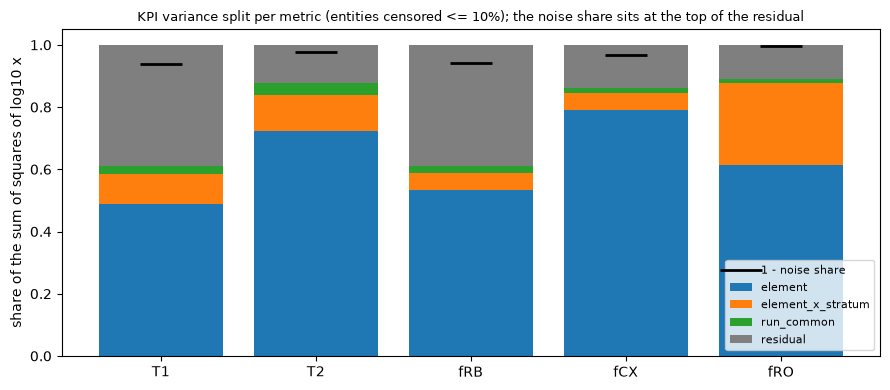

In [4]:
# Element level per metric and stratum: the mean of log10 x
N_PERM = 2000
x = d[d["cens_ok"]]
lev = x.groupby(["metric", "stratum", "unit"])["lx"].mean()

rows = []
for mt in METRICS:
    # This metric's strata in time order
    strata = lev.xs(mt).index.get_level_values("stratum").unique()
    sts = sorted(strata, key=series.stratum_order)

    for a, b in zip(sts, sts[1:]):
        # Elements seen in both strata
        la, lb = lev.xs((mt, a)), lev.xs((mt, b))
        both = la.index.intersection(lb.index)
        if len(both) < MIN_UNITS:
            continue

        # Spearman rho (Pearson on the ranks), against shuffles of the later stratum
        ra = la[both].rank().to_numpy()
        rb = lb[both].rank().to_numpy()
        rho = np.corrcoef(ra, rb)[0, 1]
        null = np.array([np.corrcoef(ra, rng.permutation(rb))[0, 1] for _ in range(N_PERM)])

        rows.append(
            {
                "metric": mt,
                "before": a,
                "after": b,
                "units": len(both),
                "rho": rho,
                "p": (1 + (null >= rho).sum()) / (1 + N_PERM),
            }
        )

rk = pd.DataFrame(rows).set_index(["metric", "before", "after"])

print(
    f"rank correlation of element-stratum means between consecutive strata (one-sided permutation p, {N_PERM} shuffles):"
)
with pd.option_context("display.float_format", "{:.3g}".format):
    display(rk)
    print("per metric: median rho and pairs with p < 0.05:")
    display(
        rk.groupby(level="metric").agg(
            pairs=("rho", "size"),
            rho_median=("rho", "median"),
            p_below_005=("p", lambda s: int((s < 0.05).sum())),
        )
    )

# Figure: the four shares stacked per metric, with 1 - noise share marked
fig, ax = plt.subplots(figsize=(9, 4))
m = vs.loc[MAIN]
bottom = np.zeros(len(m))
for p, c in zip(PARTS, ["C0", "C1", "C2", "C7"]):
    ax.bar(m.index, m[p], bottom=bottom, color=c, label=p)
    bottom += m[p].to_numpy()
ax.plot(m.index, 1 - m["noise"], "k_", ms=30, mew=2, label="1 - noise share")

ax.set_ylabel("share of the sum of squares of log10 x")
ax.legend(fontsize=8, loc="lower right")
ax.set_title(
    f"KPI variance split per metric (entities {MAIN}); the noise share sits at the top of the residual",
    fontsize=9,
)
fig.tight_layout()

out = FIG / "d1b_kpi_variance_split.png"
fig.savefig(out, dpi=120)
print("saved", out.relative_to(REPO_ROOT))

**Results.**

- **Rankings.** They hold: every consecutive pair of strata has $p$ below 0.05 in every metric, and the median $\rho$ is 0.876 (T1), 0.956 (T2), 0.956 (fCX), 0.84 (fRB) and 0.895 (fRO).
- **Lowest pairs.** fRO from stratum 9 to 11, across the thermal cycle, has $\rho = 0.49$ ($p = 0.002$). Next come T2 2 → 7 (0.64), fRB 9 → 11 (0.668) and T1 2 → 7 (0.691).

## 4. KPI steps across the windows

Now we turn from the split to chip-wide changes. Each window has a start and an end, and a step compares an element's last $K = 7$ values before the start with its first $K$ from the end, so values inside the window are left out. With $i$ the first value at or after the start and $j$ the first at or after the end,

$$
\Delta = \operatorname{median}(y_j, \dots, y_{j+K-1}) - \operatorname{median}(y_{i-K}, \dots, y_{i-1}).
$$

We take each element's step in $\log_{10} x$ (fCX per list), with $x$ = T1 or T2 in µs, or $1 - F$ - so up means longer for T1 and T2, and a larger infidelity for the fidelities. We report the median over elements with a bootstrap interval. Rows are the C1 kept rows of the main set, near-floor fRO out, in every stratum (strata 3, 4, 6 and 12 have no noise row and strata 5 and 10 no runs, so C1 doesn't use them). `first` and `last` are the median times of the first and last runs used, so a side can reach past a break next to the window (2025-03-20 after the outage).

The placebo takes the same step at every day of the record with the window's length, wherever neither side spans a break, outage, incident or thermal cycle, or overlaps a window. We compare the chip-wide median with the spread of the placebo medians around their own median, so slow drift over the gap doesn't count as a step. With $n$ placebo values, of which $n_{\ge}$ sit at least as far from the placebo median,

$$
\text{placebo\_p} = \frac{1 + n_{\ge}}{1 + n},
$$

which can't fall below $1 / (1 + n)$. `placebo_z` gives the size in robust sd of the placebo, and `beyond_own_q95` is the share of elements past their own 95% placebo |step| (about 0.05 with no step).

> **Note on the C1 windows:** C1 found 2025-12 and 2026-07 by searching these same KPIs for change points, so their placebo_p is optimistic - a step picked for its size will look large next to random days. We read them as a size check and look for an independent record of an event in sections 5 to 8. The outage and the thermal cycle come from the register, so their placebo is fair. C1 section 4 finds the fRO step at the thermal cycle and no other KPI step beyond the placebo.

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from numpy.lib.stride_tricks import sliding_window_view

from qpu_drift import periods
from qpu_drift.analysis import methods, series
from qpu_drift.analysis.constants import F01_BIG, METRICS, NEAR_EVENT
from qpu_drift.derived.noise import load_noise_floor
from qpu_drift.derived.run_map import load_run_entities, load_run_map
from qpu_drift.paths import REPO_ROOT
from qpu_drift.sources.benchmarking import load_kpi_l2, load_runs_l2
from qpu_drift.sources.benchmarking.load import KPI_SUPPLEMENTED_PATH
from qpu_drift.sources.fridge import load_fridge
from qpu_drift.sources.fridge.constants import MIX_CHANNEL as MIX
from qpu_drift.sources.hardware_models import decode_value, load_values

pd.set_option(
    "display.max_rows",
    300,
    "display.max_columns",
    40,
    "display.width",
    250,
    "display.max_colwidth",
    80,
)

# Where the figures go
FIG = REPO_ROOT / "docs" / "figures" / "hypotheses"
FIG.mkdir(parents=True, exist_ok=True)
T = pd.Timestamp

# The windows as (start, end): steps compare the values before start with the values from end
WINDOWS = {
    "outage 2025-03": periods.OUTAGES[1],
    "2025-12": (T("2025-12-15"), T("2025-12-22")),
    "thermal cycle": (periods.THERMAL_CYCLES[0][0], periods.SETTLING[0][1]),
    "2026-07": (T("2026-07-12"), T("2026-08-01")),
}

# Step settings
K_W = 7  # KPI runs per side (the C1 K_MIN window)
K_DS2 = 14  # DS2 values per side: calibrate_1q writes twice a day, so a morning and an evening value per day
CENSOR_MAX = 0.10  # entities censored above this share are left out of the main analysis
MIN_UNITS = 5  # elements needed for a chip-wide value
STOP = ["BREAK", "OUTAGE", "THERMAL_CYCLE", "INCIDENT"]  # a placebo side may not span these
DS4_SIDE = pd.Timedelta("7D")
RATE_SIDE = pd.Timedelta("14D")

# Each window with its length in days
window_text = {
    w: f"{a:%Y-%m-%d %H:%M} to {b:%Y-%m-%d %H:%M} ({(b - a) / pd.Timedelta('1D'):.3g} days)"
    for w, (a, b) in WINDOWS.items()
}
print("windows:", window_text)

# Register events a placebo side may not span, as a sorted time array
EV = series.register_events()
stop_t = np.sort(EV.loc[EV["type"].isin(STOP), "at"].to_numpy("datetime64[ns]"))

# KPI rows: kept, near-floor fRO out, entities censored at most CENSOR_MAX, every stratum
k = series.kpi_rows(load_kpi_l2(path=KPI_SUPPLEMENTED_PATH), load_runs_l2())
kept = series.kept_kpi(k)
cens = series.censored_share(k)
bad = cens[cens > CENSOR_MAX].index
near_floor_fro = kept["near_floor"] & (kept["metric"] == "fRO")
d = kept[~near_floor_fro & kept["lx"].notna()]
d = d[~pd.MultiIndex.from_frame(d[["metric", "element"]]).isin(bad)]

# One long table in time order, with y = log10 x
kr = (
    d[["metric", "unit", "t", "lx", "stratum"]]
    .rename(columns={"lx": "y"})
    .sort_values("t", ignore_index=True)
)

print(
    f"KPI rows (kept, entities censored at most {CENSOR_MAX}, near-floor fRO out) per metric:",
    kr.groupby("metric").size().to_dict(),
)
t_range = {
    mt: f"{g['t'].min():%Y-%m-%d} to {g['t'].max():%Y-%m-%d}" for mt, g in kr.groupby("metric")
}
print("first and last time per metric:", t_range)

def units(df):
    # One series per metric and unit: times and values
    for (mt, u), g in df.groupby(["metric", "unit"]):
        yield mt, u, g["t"].to_numpy("datetime64[ns]"), g["y"].to_numpy(float)

def steps_at(df: pd.DataFrame, a, b, k: int) -> pd.DataFrame:
    """Per metric and unit: median of the first k values at or after b minus the median of the
    last k before a, with the times of the first and last value used."""
    rows = []
    for mt, u, tn, y in units(df):
        # First value at or after a, and at or after b
        i = np.searchsorted(tn, np.datetime64(a))
        j = np.searchsorted(tn, np.datetime64(b))

        # Only units with k values on each side
        if i >= k and j + k <= len(y):
            step = np.median(y[j : j + k]) - np.median(y[i - k : i])
            rows.append((mt, u, tn[i - k], tn[j + k - 1], step))
    return pd.DataFrame(rows, columns=["metric", "unit", "t_first", "t_last", "step"])

def blocked(first: np.ndarray, last: np.ndarray, extra=()) -> np.ndarray:
    """True where [first, last] holds a STOP register event (or a time in extra) or overlaps one
    of the windows."""
    # An event falls inside when more events sit at or before last than at or before first
    ev = np.sort(np.concatenate([stop_t, np.asarray(extra, dtype="datetime64[ns]")]))
    out = np.searchsorted(ev, last, "right") > np.searchsorted(ev, first, "right")

    for a, b in WINDOWS.values():
        out |= (first < np.datetime64(b)) & (last > np.datetime64(a))
    return out

def placebo_at(df: pd.DataFrame, gap: pd.Timedelta, k: int) -> pd.DataFrame:
    """steps_at with a = s and b = s + gap for every day s of the record, unless blocked."""
    # Every day of the record is a placebo start
    grid = pd.date_range(df["t"].min().normalize(), df["t"].max().normalize(), freq="D")
    A = grid.to_numpy("datetime64[ns]")
    B = (grid + gap).to_numpy("datetime64[ns]")

    out = []
    for mt, u, tn, y in units(df):
        if len(y) < 2 * k:
            continue

        # Rolling medians: med[i] is the median of y[i : i + k]
        med = np.median(sliding_window_view(y, k), axis=1)

        # Placebo starts with k values on each side
        i, j = np.searchsorted(tn, A), np.searchsorted(tn, B)
        ok = (i >= k) & (j + k <= len(y))
        i, j, s = i[ok], j[ok], A[ok]

        # Drop the ones whose sides span a stop event or touch a window
        keep = ~blocked(tn[i - k], tn[j + k - 1])
        step = (med[j] - med[i - k])[keep]
        out.append(pd.DataFrame({"metric": mt, "unit": u, "s": s[keep], "step": step}))
    return pd.concat(out, ignore_index=True)

def judge(st: pd.DataFrame, pl: pd.DataFrame) -> pd.DataFrame:
    """Per metric: median step over units (bootstrap interval), share up, and the placebo.

    The placebo uses chip-wide medians per split day (5+ units): placebo_p for the distance from
    the placebo median (methods.perm_p), placebo_z in robust sd of the placebo medians, and the
    share of units beyond their own 95% placebo |step|.
    """
    rows = []
    for mt, g in st.groupby("metric"):
        if len(g) < MIN_UNITS:
            continue

        # Chip-wide placebo medians, on days with enough units
        p = pl[pl["metric"] == mt]
        pc = p.groupby("s")["step"].agg(["median", "size"])
        pc = pc.loc[pc["size"] >= MIN_UNITS, "median"]

        # Each unit's own 95% placebo |step|
        q95 = p.assign(a=p["step"].abs()).groupby("unit")["a"].quantile(0.95)
        has = g["unit"].isin(q95.index)

        # The real step, then how far it sits from the placebo median
        med, lo, hi = methods.bootstrap_median(g["step"])
        if len(pc):
            centre = pc.median()
            placebo_p = methods.perm_p((pc - centre).abs(), abs(med - centre))
        else:
            placebo_p = np.nan
        placebo_z = (med - pc.median()) / methods.rsd(pc) if len(pc) >= 3 else np.nan
        if has.any():
            beyond = float((g.loc[has, "step"].abs() > g.loc[has, "unit"].map(q95)).mean())
        else:
            beyond = np.nan

        rows.append(
            {
                "metric": mt,
                "units": len(g),
                "median": med,
                "ci_lo": lo,
                "ci_hi": hi,
                "share_up": (g["step"] > 0).mean(),
                "placebo_n": len(pc),
                "placebo_p": placebo_p,
                "placebo_z": placebo_z,
                "beyond_own_q95": beyond,
                "first": g["t_first"].median().strftime("%Y-%m-%d"),
                "last": g["t_last"].median().strftime("%Y-%m-%d"),
            }
        )
    return pd.DataFrame(rows)


windows: {'outage 2025-03': '2025-03-10 00:00 to 2025-03-18 00:00 (8 days)', '2025-12': '2025-12-15 00:00 to 2025-12-22 00:00 (7 days)', 'thermal cycle': '2026-03-09 00:00 to 2026-04-04 00:00 (26 days)', '2026-07': '2026-07-12 00:00 to 2026-08-01 00:00 (20 days)'}


KPI rows (kept, entities censored at most 0.1, near-floor fRO out) per metric: {'T1': 12267, 'T2': 7714, 'fCX': 12902, 'fRB': 12766, 'fRO': 20688}
first and last time per metric: {'T1': '2024-10-15 to 2026-09-14', 'T2': '2024-10-15 to 2026-09-14', 'fCX': '2024-10-15 to 2026-09-14', 'fRB': '2024-10-15 to 2026-09-14', 'fRO': '2024-05-24 to 2026-09-14'}


In [6]:
# KPI step across each window, judged against its gap-matched placebo
ks = []
for w, (a, b) in WINDOWS.items():
    j = judge(steps_at(kr, a, b, K_W), placebo_at(kr, b - a, K_W))
    ks.append(j.assign(window=w))
ks = pd.concat(ks, ignore_index=True)

# The step as a fraction, and Benjamini-Hochberg q over all rows
ks["pct"] = 10 ** ks["median"] - 1
ks["placebo_q"] = methods.bh(ks["placebo_p"])

cols = [
    "units",
    "median",
    "ci_lo",
    "ci_hi",
    "pct",
    "share_up",
    "placebo_n",
    "placebo_p",
    "placebo_q",
    "placebo_z",
    "beyond_own_q95",
    "first",
    "last",
]

print(
    f"KPI step across each window, K = {K_W} runs per side: median over elements of the log10 x step (bootstrap interval),",
    "pct = 10^median - 1, share up, gap-matched placebo (placebo_q: Benjamini-Hochberg over the rows):",
)
with pd.option_context("display.float_format", "{:.3g}".format):
    display(ks.set_index(["window", "metric"])[cols])

KPI step across each window, K = 7 runs per side: median over elements of the log10 x step (bootstrap interval), pct = 10^median - 1, share up, gap-matched placebo (placebo_q: Benjamini-Hochberg over the rows):


units   median    ci_lo    ci_hi      pct  share_up  placebo_n  placebo_p  placebo_q  placebo_z  beyond_own_q95       first        last
window         metric                                                                                                                                         
outage 2025-03 T1         22  -0.0283  -0.0915  0.00121  -0.0632     0.318        396      0.073      0.162      -1.91           0.136  2025-03-01  2025-03-27
               T2         14  -0.0508  -0.0948    0.316    -0.11     0.357        396      0.068      0.162      -3.31           0.429  2025-03-01  2025-03-27
               fCX        30   0.0245 -0.00423   0.0846    0.058     0.633        396      0.131      0.236        1.6           0.379  2025-03-01  2025-03-28
               fRB        24 -0.00628   -0.107    0.121  -0.0144     0.458        394      0.722      0.759     -0.365           0.417  2025-03-01  2025-03-27
               fRO        32  -0.0445  -0.0953 -0.00404  -0.0975     0.312        456    0.00219     0.0336      -5.59           0.344  2025-03-01  2025-03-27
2025-12        T1         22   0.0269  -0.0129   0.0843   0.0638     0.682        404     0.0815      0.163       1.61           0.136  2025-12-08  2025-12-29
               T2         14   0.0337   0.0037   0.0592   0.0808     0.857        404      0.153      0.236       2.37          0.0714  2025-12-08  2025-12-29
               fCX        29  -0.0482  -0.0705 -0.00655   -0.105     0.276        404     0.0148     0.0988      -3.36           0.143  2025-12-08  2025-12-29
               fRB        24  -0.0102  -0.0541   0.0367  -0.0232     0.458        402      0.628      0.738     -0.469               0  2025-12-07  2025-12-29
               fRO        32  -0.0223  -0.0511 -0.00882  -0.0501     0.188        465     0.0451      0.129      -2.99          0.0312  2025-12-08  2025-12-29
thermal cycle  T1         22 -0.00499  -0.0338    0.024  -0.0114     0.455        255      0.594      0.738     -0.584          0.0455  2026-03-02  2026-04-11
               T2         14 -0.00792   -0.214   0.0472  -0.0181     0.429        255      0.477      0.635      -0.77           0.286  2026-03-02  2026-04-11
               fCX        20  -0.0423  -0.0777   0.0518  -0.0927      0.35        255     0.0391      0.129      -2.61           0.368  2026-03-02  2026-04-11
               fRB        24  0.00145   -0.092    0.118  0.00334       0.5        254      0.847      0.847      0.202           0.292  2026-03-02  2026-04-11
               fRO        32    0.167    0.113    0.246    0.469     0.875        297    0.00336     0.0336       17.3             0.5  2026-03-02  2026-04-11
2026-07        T1         22  -0.0187  -0.0527   0.0108  -0.0421     0.364        300      0.153      0.236       -1.6           0.136  2026-07-01  2026-08-08
               T2         14 -0.00355   -0.118   0.0225 -0.00814       0.5        300      0.664      0.738     -0.433           0.143  2026-07-01  2026-08-08
               fCX        20   0.0514   0.0253   0.0864    0.126       0.8        300     0.0233      0.115       2.72           0.263  2026-07-01  2026-08-08
               fRB        24   0.0144   -0.028   0.0647   0.0337     0.542        298      0.395      0.564      0.918           0.167  2026-07-01  2026-08-09
               fRO        32   0.0313   0.0123   0.0509   0.0748     0.812        348     0.0287      0.115       3.58           0.219  2026-07-01  2026-08-08

**Results.**

- **Thermal cycle.** fRO steps +46.9% (0.875 of elements up; placebo_p 0.00336, q 0.0336, z 17.3), and 0.5 of elements are beyond their own placebo q95. T1, T2, fCX and fRB intervals include 0, with placebo_p 0.0391 (fCX) to 0.847.
- **Outage 2025-03.** fRO steps −9.75% (interval excludes 0; placebo_p 0.00219, q 0.0336, z −5.59). T1, T2, fCX and fRB intervals include 0, with placebo_p 0.068 to 0.722. The sides reach from 2025-03-01 to 03-27 or 03-28.
- **2025-12.** The intervals exclude 0 for T2 +8.08% (0.857 up; placebo_p 0.153, q 0.236), fCX −10.5% (p 0.0148, q 0.0988) and fRO −5.01% (p 0.0451, q 0.129). T1 (+6.38%) and fRB (−2.32%) include 0.
- **2026-07.** The intervals exclude 0 for fCX +12.6% (0.8 up; p 0.0233, q 0.115) and fRO +7.48% (p 0.0287, q 0.115). T1 (−4.21%), T2 and fRB include 0. The sides reach back to 2026-07-01, across the 2026-07-02 incident (its rows are out).

So only the two process events give a step that clearly beats the placebo, and only in fRO. The C1 windows give steps of 5-13% in fCX and fRO, at q 0.0988 to 0.129 before allowing for how they were picked.

## 5. 1q fields in DS2 across the windows

If the KPIs step because calibration moved, the deployed 1q fields should step too. We take the same step per qubit on the drive frequency (kHz), $\ln|\text{drive scale}|$, $\ln$ X/2 amp and X/2 drag (as stored). Each DS2 value is one point on a side, so we use $K = 14$ values per side - about a week of morning and evening writes - and the same centred placebo as section 4.

Values written inside an incident are left out, as the KPI rows are. Otherwise the 2026-07-02 shift and its rollback would land in the 14 values before 2026-07. C2 section 4 has the 2025-03 freq step run by run, and section 9 follows it into DS2.

In [7]:
# DS2 paths of the 1q fields; the group captures the qubit number
FIELDS = {
    "drive frequency": r"model\.pulse_channels\{Ch\d+\.Q(\d+)\.drive\}\.pulse_channel\.frequency",
    "drive scale": r"model\.pulse_channels\{Ch\d+\.Q(\d+)\.drive\}\.pulse_channel\.scale",
    "X/2 amp": r"model\.quantum_devices\{Q(\d+)\}\.pulse_hw_x_pi_2\{amp\}",
    "X/2 drag": r"model\.quantum_devices\{Q(\d+)\}\.pulse_hw_x_pi_2\{drag\}",
}
hv = load_values()

# One long table of field values: kHz for frequency, ln for scale and amp, drag as stored
parts = []
for name, pat in FIELDS.items():
    x = hv[hv["path"].str.fullmatch(pat.replace("(\\d+)", "\\d+"))]

    if name == "drive scale":
        # The scale is complex, so we take the log of its magnitude
        y = np.log(x.apply(decode_value, axis=1).map(lambda z: abs(complex(z))))
    else:
        y = x["value_float"].fillna(x["value_int"])
        if name == "X/2 amp":
            y = np.log(y.abs())
        elif name == "drive frequency":
            y = y / 1e3

    parts.append(
        pd.DataFrame(
            {
                "metric": name,
                "unit": x["path"].str.extract(pat)[0].astype(int),
                "t": x["valid_from_ts"],
                "y": y,
            }
        )
    )

dv = pd.concat(parts, ignore_index=True).dropna(subset=["y"]).sort_values("t", ignore_index=True)

# Values written inside an incident stay out of the steps (section 8 counts them apart)
inc = [i.period for i in periods.INCIDENTS]
dv_step = dv[~periods.within(dv["t"], *inc)]
print(
    "DS2 value rows per field:",
    dv.groupby("metric").size().to_dict(),
    f"from {dv['t'].min():%Y-%m-%d} to {dv['t'].max():%Y-%m-%d};",
    f"{len(dv) - len(dv_step)} written inside an incident are left out of the steps",
)

# DS2 step across each window, judged against its gap-matched placebo
qs = []
for w, (a, b) in WINDOWS.items():
    j = judge(steps_at(dv_step, a, b, K_DS2), placebo_at(dv_step, b - a, K_DS2))
    qs.append(j.assign(window=w))
qs = pd.concat(qs, ignore_index=True)
qs["placebo_q"] = methods.bh(qs["placebo_p"])

cols = [
    "units",
    "median",
    "ci_lo",
    "ci_hi",
    "share_up",
    "placebo_n",
    "placebo_p",
    "placebo_q",
    "placebo_z",
    "beyond_own_q95",
    "first",
    "last",
]

print(
    f"DS2 1q step across each window, K = {K_DS2} values per side: median over qubits (kHz for drive frequency, ln for",
    "drive scale and X/2 amp, drag as stored), share up, gap-matched placebo:",
)
with pd.option_context("display.float_format", "{:.3g}".format):
    display(qs.set_index(["window", "metric"])[cols])

DS2 value rows per field: {'X/2 amp': 34369, 'X/2 drag': 31977, 'drive frequency': 33176, 'drive scale': 35435} from 2025-01-01 to 2026-08-18; 1178 written inside an incident are left out of the steps
DS2 1q step across each window, K = 14 values per side: median over qubits (kHz for drive frequency, ln for drive scale and X/2 amp, drag as stored), share up, gap-matched placebo:


units    median     ci_lo    ci_hi  share_up  placebo_n  placebo_p  placebo_q  placebo_z  beyond_own_q95       first        last
window         metric                                                                                                                                           
outage 2025-03 X/2 amp             32   0.00313  0.000932  0.00566     0.688        309     0.0935      0.214       1.79            0.25  2025-03-02  2025-03-24
               X/2 drag            30  -4.3e-11 -1.48e-10  4.5e-11     0.467        308    0.00324     0.0212      -20.3           0.833  2025-03-02  2025-03-24
               drive frequency     30 -1.27e+03 -2.22e+03      537     0.367        309    0.00323     0.0212       -883           0.967  2025-03-02  2025-03-24
               drive scale         32  -0.00586    -0.027  0.00616     0.344        309     0.0161     0.0516      -2.28            0.75  2025-03-02  2025-03-24
2025-12        X/2 amp             32   0.00219   0.00123  0.00357      0.75        316      0.249      0.399       1.25               0  2025-12-08  2025-12-28
               X/2 drag            30  1.73e-12 -2.75e-12 6.45e-12     0.533        315      0.386      0.523      0.888          0.0667  2025-12-08  2025-12-28
               drive frequency     30      -1.9     -4.65     -0.7     0.267        316      0.202      0.385      -1.37               0  2025-12-08  2025-12-28
               drive scale         32  -0.00172  -0.00324 -0.00028     0.281        316      0.404      0.523     -0.858               0  2025-12-08  2025-12-28
thermal cycle  X/2 amp             32  -0.00148  -0.00265 0.000673     0.406        189      0.547      0.584     -0.566           0.188  2026-03-02  2026-04-10
               X/2 drag            30  3.32e-11 -1.05e-10 1.98e-10       0.5        188    0.00529     0.0212         12           0.867  2026-03-02  2026-04-10
               drive frequency     30 -1.28e+03 -2.87e+03      268       0.4        189    0.00526     0.0212       -478             0.9  2026-03-02  2026-04-10
               drive scale         32  -0.00694   -0.0411  0.00082     0.344        189     0.0421      0.112      -2.93           0.688  2026-03-02  2026-04-10
2026-07        X/2 amp             32  -0.00211  -0.00385 0.000248     0.344        225      0.469      0.536     -0.713           0.156  2026-07-01  2026-08-08
               X/2 drag            30 -2.47e-13 -7.79e-12 2.59e-11       0.5        224      0.991      0.991    -0.0213           0.267  2026-07-01  2026-08-08
               drive frequency     30      1.41     -1.37     13.9     0.533        225      0.425      0.523      0.787           0.167  2026-07-01  2026-08-08
               drive scale         32   0.00431   0.00187  0.00555     0.844        225      0.217      0.385       1.33          0.0938  2026-07-01  2026-08-08

**Results.**

1,178 DS2 values written inside an incident are left out.

- **Outage 2025-03.** The drive frequency steps −1.27e+03 kHz (interval −2.22e+03 to 537; placebo_p 0.00323, q 0.0212; 0.967 of qubits beyond their own q95) and X/2 drag −4.3e-11 (p 0.00324, q 0.0212; 0.833). Drive scale −0.00586 ln (p 0.0161, q 0.0516; 0.75); X/2 amp p 0.0935.
- **Thermal cycle.** The drive frequency steps −1.28e+03 kHz (p 0.00526, q 0.0212; 0.9 beyond) and X/2 drag +3.32e-11 (p 0.00529, q 0.0212; 0.867). Drive scale p 0.0421 (q 0.112), X/2 amp 0.547.
- **2025-12 and 2026-07.** Nothing beats the placebo: placebo_p is 0.202 to 0.404 in 2025-12 and 0.217 to 0.991 in 2026-07, and the share beyond own q95 is 0 to 0.0667 and 0.0938 to 0.267. A few intervals exclude 0 at small sizes: in 2025-12 X/2 amp +0.00219 ln, drive frequency −1.9 kHz and drive scale −0.00172 ln; in 2026-07 drive scale +0.00431 ln.

The wide drive-frequency intervals at the process events come from qubits stepping both ways, while nearly every qubit moves beyond its own placebo.

## 6. DS2 writes and the register in each window

We widen each window by 2 days on each side (the C1 matching distance) and look at the DS2 changes per path template. For each template we note the share of changes in snapshots that no tracked run wrote (no run's `snap_after`), and its change rate in the window over its rate across the whole DS2 record. Then we list every no-run snapshot in the window with 10 or more changes, and the register entries.

In [8]:
# Which routine wrote each snapshot (snapshots no run wrote are "no run")
rm = load_run_map()
made_by = rm.dropna(subset=["snap_after"]).groupby("snap_after")["routine"].agg(", ".join)

# A change is a path's value after its first snapshot
first_seen = hv.groupby("path")["valid_from_ts"].transform("min")
ch = hv.loc[hv["valid_from_ts"] > first_seen, ["path", "path_template", "valid_from_ts"]].rename(
    columns={"valid_from_ts": "at"}
)
ch["writer"] = ch["at"].map(made_by).fillna("no run")

# Each template's change rate per day over the whole record
span_days = (ch["at"].max() - ch["at"].min()) / pd.Timedelta("1D")
base_rate = ch.groupby("path_template").size() / span_days
print(
    f"DS2 changes (a path's value after its first snapshot): {len(ch):,} over {span_days:.4g} days"
)

for w, (a, b) in WINDOWS.items():
    # The window widened by the matching distance on each side
    lo, hi = a - NEAR_EVENT, b + NEAR_EVENT
    c = ch[(ch["at"] >= lo) & (ch["at"] < hi)]
    days = (hi - lo) / pd.Timedelta("1D")

    # Per template: changes, the no-run share and the rate against the whole record
    tab = c.groupby("path_template").agg(
        changes=("path", "size"),
        paths=("path", "nunique"),
        snapshots=("at", "nunique"),
        no_run=("writer", lambda s: (s == "no run").mean()),
    )
    tab["rate_ratio"] = tab["changes"] / days / base_rate.reindex(tab.index)

    print(
        f"\n{w}: {lo:%Y-%m-%d} to {hi:%Y-%m-%d} ({days:.3g} days), {len(c):,} changes; per template (10+ changes):"
    )
    with pd.option_context("display.float_format", "{:.3g}".format):
        display(tab[tab["changes"] >= 10].sort_values("changes", ascending=False))

    # No-run snapshots, with their size and top template
    nr = (
        c[c["writer"] == "no run"]
        .groupby("at")
        .agg(
            changes=("path", "size"),
            templates=("path_template", "nunique"),
            top=("path_template", lambda s: s.value_counts().index[0]),
        )
    )
    print("no-run snapshots with 10+ changes:")
    display(nr[nr["changes"] >= 10])

    # Register entries in the widened window
    reg = EV.loc[(EV["at"] >= lo) & (EV["at"] < hi)]
    reg = reg.assign(at=reg["at"].dt.strftime("%Y-%m-%d %H:%M"))
    print("register entries:", reg[["at", "label"]].to_dict("records"))

DS2 changes (a path's value after its first snapshot): 678,153 over 594 days

outage 2025-03: 2025-03-08 to 2025-03-20 (12 days), 3,767 changes; per template (10+ changes):


,changes,paths,snapshots,no_run,rate_ratio
path_template,,,,,
model.pulse_channels{Ch*.Q*.Q*.cross_resonance_cancellation}.pulse_channel.frequency,364,64,6,0.176,0.272
model.pulse_channels{Ch*.Q*.Q*.cross_resonance}.pulse_channel.frequency,364,64,6,0.176,0.272
model.quantum_devices{Q*}.mean_z_map_args,288,32,9,0.111,0.27
model.pulse_channels{Ch*.Q*.drive}.pulse_channel.scale,192,32,6,0.167,0.268
model.quantum_devices{Q*}.pulse_hw_x_pi_2{amp},191,32,6,0.168,0.275
model.quantum_devices{Q*}.pulse_hw_zx_pi_4{Q*}{amp},184,32,6,0.174,0.28
model.pulse_channels{Ch*.Q*.Q*.cross_resonance}.pulse_channel.scale,184,32,6,0.174,0.28
model.quantum_devices{Q*}.phase_comp_target_zx_pi_4{Q*},184,32,6,0.174,0.28
model.pulse_channels{Ch*.Q*.Q*.cross_resonance_cancellation}.pulse_channel.scale,184,32,6,0.174,0.28


no-run snapshots with 10+ changes:


,changes,templates,top
at,,,
2025-03-18 11:42:44,163,4,model.physical_channels{Ch*}.imbalance
2025-03-18 19:06:53,505,19,model.pulse_channels{Ch*.Q*.Q*.cross_resonance_cancellation}.pulse_channel.f...


register entries: [{'at': '2025-03-10 00:00', 'label': 'OUTAGE start'}, {'at': '2025-03-18 00:00', 'label': 'BREAK 2025-03-18 outage ends (hand-written DS2 values)'}, {'at': '2025-03-18 00:00', 'label': 'OUTAGE end'}, {'at': '2025-03-18 11:42', 'label': 'UNTRACKED_DS2'}, {'at': '2025-03-18 19:06', 'label': 'UNTRACKED_DS2'}]

2025-12: 2025-12-13 to 2025-12-24 (11 days), 13,169 changes; per template (10+ changes):


...

register entries: [{'at': '2026-03-09 00:00', 'label': 'THERMAL_CYCLE start'}, {'at': '2026-03-09 08:45', 'label': 'INCIDENT start'}, {'at': '2026-03-09 19:42', 'label': 'F01_FLAG start'}, {'at': '2026-03-12 00:00', 'label': 'OUTAGE start'}, {'at': '2026-03-17 00:00', 'label': 'DS4_GAP start'}, {'at': '2026-03-17 18:00', 'label': 'DS4_GAP end'}, {'at': '2026-03-22 00:00', 'label': 'THERMAL_CYCLE end'}, {'at': '2026-03-22 00:00', 'label': 'BREAK 2026-03-22 thermal cycle ends (f01 level shift)'}, {'at': '2026-03-24 00:00', 'label': 'OUTAGE end'}, {'at': '2026-03-24 00:00', 'label': 'BREAK 2026-03-24 couplings 1-10 and 1-2 reverse'}, {'at': '2026-03-24 12:03', 'label': 'UNTRACKED_DS2'}, {'at': '2026-03-24 14:45', 'label': 'UNTRACKED_DS2_OTHER'}, {'at': '2026-03-24 14:45', 'label': 'F01_FLAG end'}, {'at': '2026-03-24 14:45', 'label': 'INCIDENT end'}]

2026-07: 2026-07-10 to 2026-08-03 (24 days), 27,512 changes; per template (10+ changes):


,changes,paths,snapshots,no_run,rate_ratio
path_template,,,,,
model.pulse_channels{Ch*.Q*.Q*.cross_resonance_cancellation}.pulse_channel.frequency,2880,60,48,0,1.07
model.pulse_channels{Ch*.Q*.Q*.cross_resonance}.pulse_channel.frequency,2880,60,48,0,1.07
model.quantum_devices{Q*}.mean_z_map_args,2240,32,70,0,1.05
model.pulse_channels{Ch*.Q*.drive}.pulse_channel.scale,1536,32,48,0,1.07
model.quantum_devices{Q*}.pulse_hw_x_pi_2{amp},1533,32,48,0,1.11
model.error_mitigation.readout_mitigation.linear{*}{0|1},1519,32,48,0,1.08
model.error_mitigation.readout_mitigation.linear{*}{1|1},1519,32,48,0,1.08
model.error_mitigation.readout_mitigation.linear{*}{1|0},1509,32,48,0,1.08
model.error_mitigation.readout_mitigation.linear{*}{0|0},1509,32,48,0,1.08


no-run snapshots with 10+ changes:


,changes,templates,top
at,,,


register entries: []


**Results.**

- **Outage 2025-03** (2025-03-08 to 03-20, 3,767 changes). Rate ratios are 0.218 to 0.472 per template, with no-run shares 0 to 0.395. The exception is `second_state` frequency and scale: they change only in one no-run snapshot, at rate ratio about 42. Two no-run snapshots have 10+ changes, both on 2025-03-18 and both with an `UNTRACKED_DS2` entry: 11:42:44 (163 changes, 4 templates, top the mixer `imbalance`) and 19:06:53 (505, 19 templates, top the CRC frequency).
- **2025-12** (2025-12-13 to 12-24, 13,169 changes) **and 2026-07** (2026-07-10 to 08-03, 27,512). Nothing out of the ordinary: the no-run share is 0 for every template, rate ratios are 1 to 1.39 (DC bias I the highest) and 0.906 to 1.11, no no-run snapshot has 10+ changes, and the register has no entry.
- **Thermal cycle** (2026-03-07 to 04-06, 19,736 changes). Eight no-run snapshots have 10+ changes, from 2026-03-24 12:03:12 (806 changes, 21 templates) to 03-30 19:05:15 (22, top `mean_z_map_args`). The first two have register entries (`UNTRACKED_DS2`, `UNTRACKED_DS2_OTHER`), the other six none. The readout fields (`pulse_measure` amp, measure and acquire frequency) change only in no-run snapshots here, at rate ratios 2.06 to 3.48.


## 7. DS4 across the windows

For each representative channel (B1 section 3) we take the change in the median of the cold rows from the 7 days before the window to the 7 days from its end. We only keep rows inside B1's settled windows, so the days after a warm-up or a DS4 gap don't count as a change - without this, the side before 2026-07 would reach into the unsettled rows after the 2026-07-02 incident.

The placebo is the same difference at every day of the DS4 record, where the sides don't span a DS4 gap, a STOP event or the edge of a settled window, and don't overlap a window. placebo_p is measured from the placebo median, as in sections 4 and 5. DS4 starts on 2025-08-01, so the 2025-03 outage has no row.

In [9]:
# B1 section 3 representative channels
REPS = [
    MIX,
    "temperature_DRI_CLD_S",
    "temperature_DRI_STL_S",
    "temperature_DRI_PT2_S",
    "temperature_DRI_PT1_S",
    "outlet_water_temperature_3CL_PTR_3CL_PTR_02",
    "flow_3CL_FM_01",
    "oil_temperature_3CL_PTR_3CL_PTR_01",
]

# B1's settled windows: one MIX noise row per epoch (UTC, no timezone)
nzf = load_noise_floor()
settled = nzf.loc[
    (nzf["source"] == "ds4") & (nzf["param"] == MIX) & (nzf["method"] == "lag1_robust_over_sqrt2"),
    ["regime", "start", "end"],
].sort_values("start")
print("B1 settled windows:", {r.regime: f"{r.start:%Y-%m-%d %H:%M} to {r.end:%Y-%m-%d %H:%M}" for r in settled.itertuples()})

# Cold rows inside a settled window, with times as naive UTC
fr = load_fridge(cold=True)[REPS]
fr.index = fr.index.tz_convert("UTC").tz_localize(None).astype("datetime64[ns]")
in_settled = np.zeros(len(fr), dtype=bool)
for s, e in zip(settled["start"], settled["end"]):
    in_settled |= (fr.index >= s) & (fr.index <= e)
fr = fr[in_settled]
print(f"DS4 settled cold rows {len(fr):,}, {fr.index.min():%Y-%m-%d} to {fr.index.max():%Y-%m-%d}")

# DS4 gap edges and settled-window edges, which a placebo side may not span either
edges = [t for p in periods.DS4_GAPS for t in p] + list(settled["start"]) + list(settled["end"])


def side_diff(a, b):
    # Median of the side from b minus the median of the side before a
    before = fr[(fr.index >= a - DS4_SIDE) & (fr.index < a)]
    after = fr[(fr.index >= b) & (fr.index < b + DS4_SIDE)]
    return after.median() - before.median(), len(before), len(after)


rows = []
for w, (a, b) in WINDOWS.items():
    # Skip windows that start before DS4 does
    if a - DS4_SIDE < fr.index.min():
        continue
    diff, nb, na = side_diff(a, b)

    # Placebo: the same difference at every allowed day of the record
    grid = pd.date_range(
        fr.index.min().normalize() + DS4_SIDE,
        fr.index.max().normalize() - DS4_SIDE - (b - a),
        freq="D",
    )
    ok = ~blocked(
        (grid - DS4_SIDE).to_numpy("datetime64[ns]"),
        (grid + (b - a) + DS4_SIDE).to_numpy("datetime64[ns]"),
        edges,
    )
    pl = pd.DataFrame([side_diff(s, s + (b - a))[0] for s in grid[ok]])

    for ch_ in REPS:
        p = pl[ch_].dropna()

        # p for |diff - placebo median|, z in robust sd of the placebo
        if len(p):
            placebo_p = methods.perm_p((p - p.median()).abs(), abs(diff[ch_] - p.median()))
        else:
            placebo_p = np.nan
        placebo_z = (diff[ch_] - p.median()) / methods.rsd(p) if len(p) >= 3 else np.nan

        rows.append(
            {
                "window": w,
                "channel": ch_,
                "rows_before": nb,
                "rows_after": na,
                "diff": diff[ch_],
                "placebo_n": len(p),
                "placebo_p": placebo_p,
                "placebo_z": placebo_z,
            }
        )

ds4 = pd.DataFrame(rows).set_index(["window", "channel"])
print(
    "DS4 representatives, settled cold rows: median of the 7 days from the window end minus the 7 days before its start",
    "(native units, K for temperatures), against the placebo (p for |diff - placebo median|):",
)
with pd.option_context("display.float_format", "{:.3g}".format):
    display(ds4)

B1 settled windows: {'epoch 0': '2025-08-03 00:00 to 2026-03-09 00:00', 'epoch 1': '2026-04-04 00:00 to 2026-06-11 18:00', 'epoch 3': '2026-07-08 00:00 to 2026-09-03 12:00'}
DS4 settled cold rows 1,376, 2025-08-03 to 2026-09-03
DS4 representatives, settled cold rows: median of the 7 days from the window end minus the 7 days before its start (native units, K for temperatures), against the placebo (p for |diff - placebo median|):


rows_before  rows_after      diff  placebo_n  placebo_p  placebo_z
window        channel                                                                                                        
2025-12       temperature_DRI_MIX_CL_DRI_MIX_S                      28          28  0.000108        190       0.56      0.546
              temperature_DRI_CLD_S                                 28          28  4.76e-05        190       0.77      0.262
              temperature_DRI_STL_S                                 28          28   0.00035        182      0.956     0.0674
              temperature_DRI_PT2_S                                 28          28    0.0128        182      0.492      0.715
              temperature_DRI_PT1_S                                 28          28     0.435        182      0.781      0.274
              outlet_water_temperature_3CL_PTR_3CL_PTR_02           28          28    0.0606        190      0.707      0.399
              flow_3CL_FM_01                                        28          28  3.64e-06        190      0.309       1.03
              oil_temperature_3CL_PTR_3CL_PTR_01                    28          28    0.0983        190      0.545      0.562
thermal cycle temperature_DRI_MIX_CL_DRI_MIX_S                      28          28    0.0007        120      0.116       2.44
              temperature_DRI_CLD_S                                 28          28  -0.00118        120    0.00826      -14.1
              temperature_DRI_STL_S                                 28          28   -0.0142        120    0.00826        -16
              temperature_DRI_PT2_S                                 28          28    -0.154        120    0.00826      -23.1
              temperature_DRI_PT1_S                                 28          28      -7.5        120    0.00826      -28.5
              outlet_water_temperature_3CL_PTR_3CL_PTR_02           28          28    0.0811        120      0.504       0.68
              flow_3CL_FM_01                                        28          28 -3.87e-05        120    0.00826      -26.1
              oil_temperature_3CL_PTR_3CL_PTR_01                    28          28      1.06        120    0.00826       3.24
2026-07       temperature_DRI_MIX_CL_DRI_MIX_S                      13          27 -0.000185        138       0.64     -0.471
              temperature_DRI_CLD_S                                 13          27  4.42e-05        138      0.719     -0.359
              temperature_DRI_STL_S                                 13          27     0.001        138      0.669      0.482
              temperature_DRI_PT2_S                                 13          27    0.0154        138      0.576      0.558
              temperature_DRI_PT1_S                                 13          27     0.886        138      0.201       1.57
              outlet_water_temperature_3CL_PTR_3CL_PTR_02           13          27     0.005        138      0.921     -0.116
              flow_3CL_FM_01                                        13          27  4.56e-06        138      0.633       0.46
              oil_temperature_3CL_PTR_3CL_PTR_01                    13          27     0.186        138      0.353      0.862

**Results.**

The settled windows keep 1,376 cold rows, from 2025-08-03 to 2026-09-03.

- **Thermal cycle.** CLD (−0.00118 K), STL (−0.0142 K), PT2 (−0.154 K), PT1 (−7.5 K), flow (−3.87e-05) and oil (+1.06 K) all have placebo_p 0.00826, the floor for 120 placebo values (z −28.5 to +3.24). MIX (+0.0007 K, p 0.116) and outlet water (p 0.504) don't.
- **2025-12.** placebo_p 0.309 to 0.956 on all eight channels; MIX +0.000108 K.
- **2026-07.** placebo_p 0.201 to 0.921 on all eight channels; MIX −0.000185 K. The side before keeps 13 rows (2026-07-08 to 07-12) and the side after 27.

## 8. Large f01 moves around the windows

A large move is a change of F01_BIG (100 kHz) or more in a qubit's applied f01 between consecutive calibrate_1q runs, unless it undoes the change before it. `series.f01_moves` labels the moves. It splits each qubit's rows into segments at gaps over 7 days, and we also split them at each incident start and each untracked DS2 edit that touched calibrate_1q. A change across a segment boundary is not a move.

A warned calibrate_1q run can leave the applied f01 off for the next runs, so f01 can move without the qubit moving. `f01_moves` marks a move as controller-affected when any run that sets it warned. We count clean and controller-affected moves apart.

We count moves per qubit-day in the 14 days before each window, inside it and in the 14 days from its end. An incident shifts f01 on most of the chip at once, and the 2026-07-02 incident sits inside the 14 days before 2026-07. So we count all moves on the full series, with segments split only at the strata, but the rates use the rows outside incidents and flagged f01, over the days outside incidents. The reference is the clean rate over every 14-day stretch of the record that doesn't touch an incident.


In [10]:
# Applied f01 per qubit and calibrate_1q run
runs1q = load_run_map(routine="calibrate_1q")
r1q = series.onevq_rows(load_run_entities(routine="calibrate_1q"), runs1q)
cols = ["qubit", "run", "t", "value", "warned", "incident", "f01_flag", "stratum"]
fa = r1q.loc[r1q["param"] == "freq", cols].rename(columns={"value": "y_hz"})
nq = fa["qubit"].nunique()

# All moves: the full series, segments split only at the strata
every = series.f01_moves(fa.assign(seg=fa["stratum"]))

# Clean and controller-affected moves: incidents and flagged f01 out, segments also split at
# each incident start and each untracked DS2 edit that touched calibrate_1q
cuts = [i.period[0] for i in periods.INCIDENTS]
cuts += [u.at for u in periods.UNTRACKED_DS2 if "calibrate_1q" in u.routines]
cut_times = np.sort(np.array(cuts, dtype="datetime64[ns]"))
fc = fa[~(fa["incident"] | fa["f01_flag"])]
cut_no = np.searchsorted(cut_times, fc["t"].to_numpy("datetime64[ns]"), side="left")
labelled = series.f01_moves(fc.assign(seg=fc["stratum"] + " c" + pd.Series(cut_no, index=fc.index).astype(str)))


def move_times(x: pd.DataFrame) -> pd.Series:
    """Times of the large moves that hold or go out (a back is the second half of an out)."""
    return x.loc[(x["d"].abs() >= F01_BIG) & (x["kind"] != "back"), "t"]


times = {
    "all": move_times(every),
    "clean": move_times(labelled[~labelled["ctrl"]]),
    "controller-affected": move_times(labelled[labelled["ctrl"]]),
}


def incident_days(lo, hi):
    # Days of [lo, hi) that fall inside an incident
    return sum(max((min(hi, e) - max(lo, s)) / pd.Timedelta("1D"), 0.0) for s, e in inc)


def rate(lo, hi) -> dict:
    """Moves of each kind in [lo, hi), the days outside incidents, and the clean and
    controller-affected rates per qubit-day outside incidents."""
    days_out = (hi - lo) / pd.Timedelta("1D") - incident_days(lo, hi)
    n = {name: int(((t >= lo) & (t < hi)).sum()) for name, t in times.items()}
    out = {f"{name} moves": v for name, v in n.items()} | {"days_outside_incidents": days_out}
    for name in ["clean", "controller-affected"]:
        out[f"{name} rate"] = n[name] / nq / days_out if days_out > 0 else np.nan
    return out


# Reference stretches: 14-day spans that don't touch an incident
grid = pd.date_range(fa["t"].min().normalize(), fa["t"].max().normalize() - RATE_SIDE, freq="D")
stretches = [s for s in grid if incident_days(s, s + RATE_SIDE) == 0]
ref = pd.Series([rate(s, s + RATE_SIDE)["clean rate"] for s in stretches])

ref_q = {q: round(float(ref.quantile(q)), 4) for q in (0.05, 0.5, 0.95)}
n_moves = {name: len(t) for name, t in times.items()}
print(
    f"applied f01 rows {len(fa):,} on {nq} qubits; moves of {F01_BIG:g} kHz or more: {n_moves};",
    f"clean rate per qubit-day over {len(ref)} 14-day stretches clear of incidents: quantiles",
    ref_q,
    f"max {ref.max():.4g}",
)

# Rates before, inside and after each window, against the reference
rows = []
for w, (a, b) in WINDOWS.items():
    sides = {
        "before": (a - RATE_SIDE, a),
        "inside": (a, b),
        "after": (b, b + RATE_SIDE),
    }
    for side, (lo, hi) in sides.items():
        r = rate(lo, hi)
        r_clean = r["clean rate"]
        share = (ref >= r_clean).mean() if np.isfinite(r_clean) else np.nan
        rows.append({"window": w, "side": side} | r | {"share_of_ref_at_or_above": share})

print("large f01 moves per window side; rates per qubit-day outside incidents:")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(pd.DataFrame(rows).set_index(["window", "side"]))


applied f01 rows 37,882 on 33 qubits; moves of 100 kHz or more: {'all': 984, 'clean': 132, 'controller-affected': 545}; clean rate per qubit-day over 821 14-day stretches clear of incidents: quantiles {0.05: 0.0, 0.5: 0.0022, 0.95: 0.0173} max 0.0303
large f01 moves per window side; rates per qubit-day outside incidents:


all moves  clean moves  controller-affected moves  days_outside_incidents  clean rate  controller-affected rate  share_of_ref_at_or_above
window         side                                                                                                                                             
outage 2025-03 before         14           10                          4                      14      0.0216                   0.00866                    0.0292
               inside          0            0                          0                       8           0                         0                         1
               after          43            8                         21                      14      0.0173                    0.0455                    0.0719
2025-12        before          1            0                          1                      14           0                   0.00216                         1
               inside          1            0                          1                       7           0                   0.00433                         1
               after           0            0                          0                      14           0                         0                         1
thermal cycle  before          8            3                          3                      14     0.00649                   0.00649                       0.3
               inside        138           10                         16                    10.7      0.0282                    0.0451                   0.00244
               after          19            6                         13                      14       0.013                    0.0281                     0.141
2026-07        before        158            1                         18                    10.5      0.0029                    0.0522                     0.385
               inside         53            8                         45                      20      0.0121                    0.0682                     0.141
               after          39            5                         34                      14      0.0108                    0.0736                     0.199

saved docs/figures/hypotheses/d1b_chipwide_changes.png


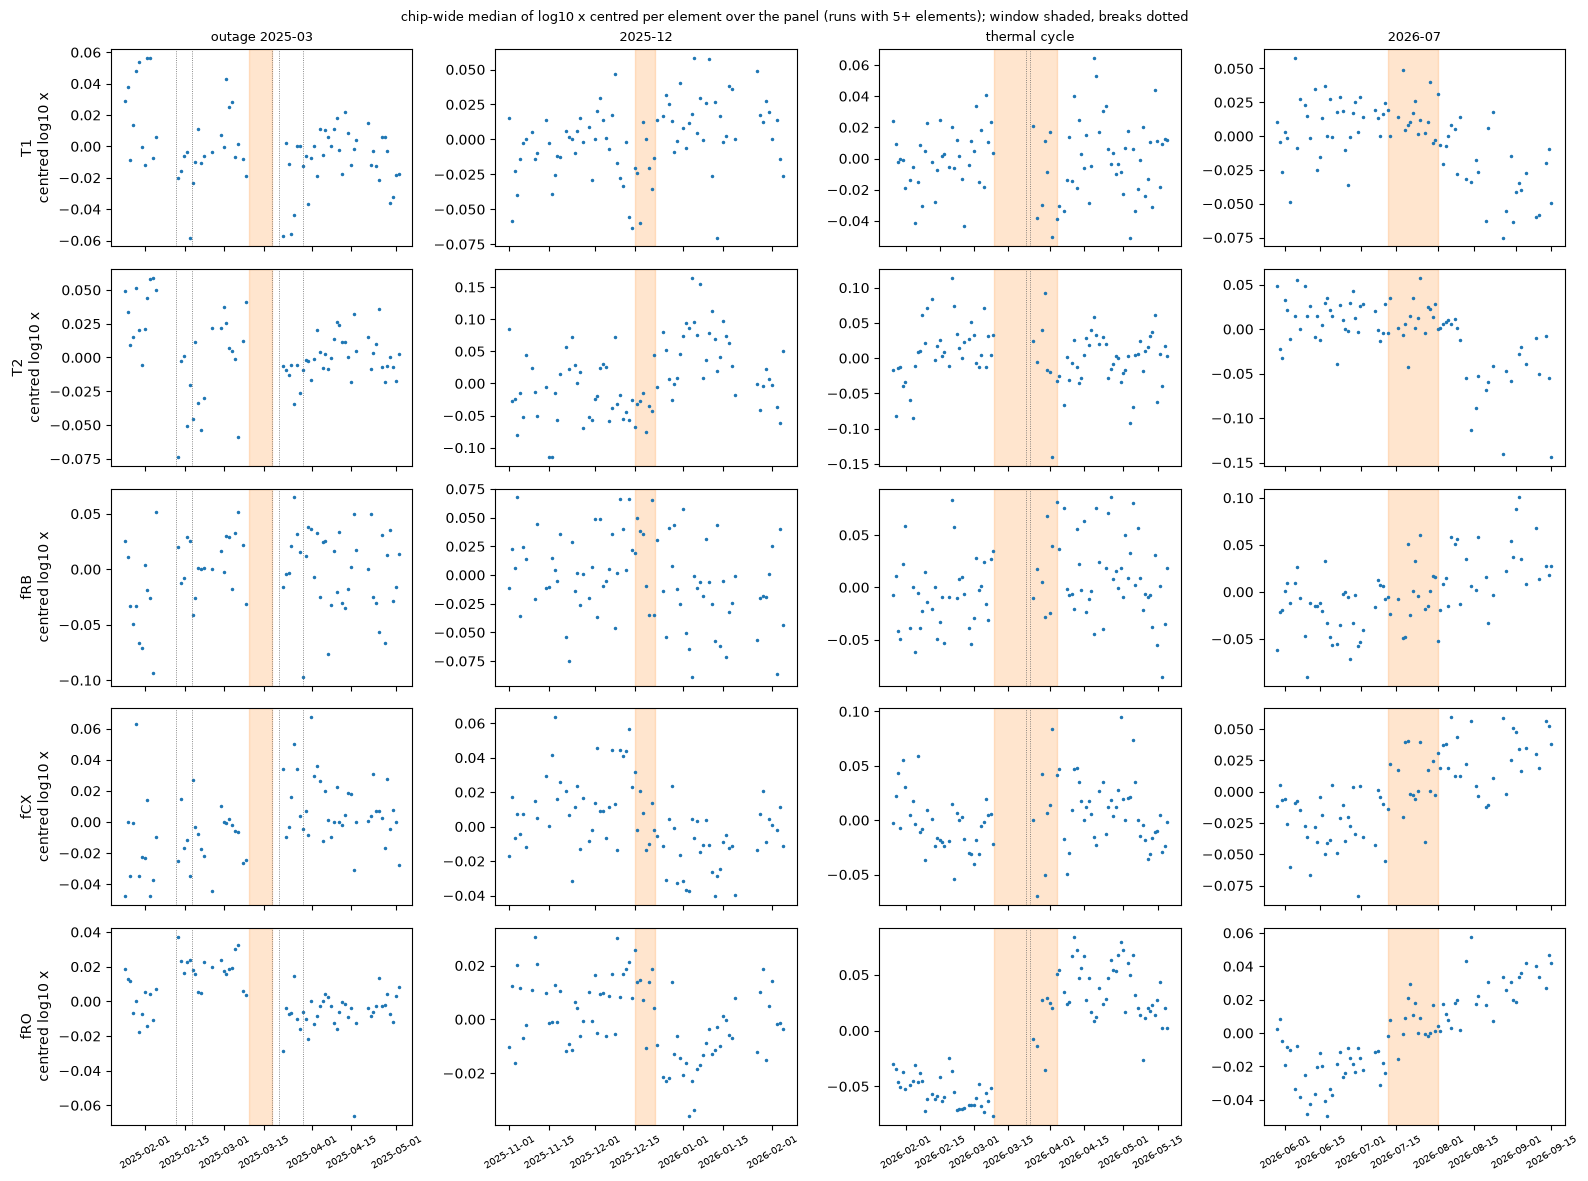

In [11]:
# Figure: chip-wide median per metric (rows) around each window (columns)
fig, axes = plt.subplots(len(METRICS), len(WINDOWS), figsize=(16, 12), sharex="col")
PAD = pd.Timedelta("45D")

for c, (w, (a, b)) in enumerate(WINDOWS.items()):
    # Rows near the window, centred per element over the panel
    x = kr[(kr["t"] >= a - PAD) & (kr["t"] < b + PAD)]
    x = x.assign(yc=x["y"] - x.groupby(["metric", "unit"])["y"].transform("median"))

    # Chip-wide median per run time, where enough elements report
    cw = x.groupby(["metric", "t"]).agg(y=("yc", "median"), n=("unit", "nunique")).reset_index()
    cw = cw[cw["n"] >= MIN_UNITS]

    for r, mt in enumerate(METRICS):
        ax = axes[r, c]
        g = cw[cw["metric"] == mt]
        ax.plot(g["t"], g["y"], ".", ms=3)

        # Shade the window and mark the breaks in view
        ax.axvspan(a, b, color="C1", alpha=0.2)
        for e in EV.loc[EV["type"] == "BREAK", "at"]:
            if a - PAD <= e < b + PAD:
                ax.axvline(e, color="0.4", lw=0.6, ls=":")

        if c == 0:
            ax.set_ylabel(f"{mt}\ncentred log10 x")
        if r == 0:
            ax.set_title(w, fontsize=9)
        ax.tick_params(axis="x", labelsize=7, rotation=30)

fig.suptitle(
    "chip-wide median of log10 x centred per element over the panel (runs with 5+ elements); window shaded, breaks dotted",
    fontsize=9,
)
fig.tight_layout()

out = FIG / "d1b_chipwide_changes.png"
fig.savefig(out, dpi=120)
print("saved", out.relative_to(REPO_ROOT))

**Results.**

- **Counts.** The full series has 984 moves of 100 kHz or more. Outside incidents and flagged f01, 132 are clean and 545 controller-affected. Over 821 reference stretches the clean rate per qubit-day has a median of 0.0022 and a 95% quantile of 0.0173.
- **Process events.** Two sides beat nearly every reference stretch: inside the thermal cycle (clean rate 0.0282, 0.0024 of stretches at or above) and the 14 days before the 2025-03 outage (0.0216, 0.0292). The 14 days after the outage are high too (0.0173, 0.0719).
- **2025-12 and 2026-07.** 2025-12 has no clean moves on any side. Around 2026-07 the clean rate is ordinary (0.141 to 0.385 of stretches at or above), but the controller-affected rate is the highest of any side (0.0522 to 0.0736). 139 of the 158 moves before 2026-07 fall on incident or flagged rows.


## 9. Lead checks: 2025-03 and 2025-02-12

C2 section 4 places freq's 4 → 7 step between the 2025-03-09 and 03-19 runs, across the outage. It also finds chip-wide amp_x_scale and drag steps at 2 → 4, and places the amp_x_scale step at 2025-02-12, the end of the earlier outage. Here we follow both into DS2.

For 2025-03 we take the applied f01 step per qubit across every calibrate_1q gap of 2+ days - the median of its first 7 runs after the gap minus its last 7 before, in kHz:

$$
\Delta_q = \operatorname{median}\left(f_{q,\text{after}}\right) - \operatorname{median}\left(f_{q,\text{before}}\right).
$$

BIG_STEP is the 99% quantile of $|\Delta_q|$ over 300 random splits between runs whose windows hold no long gap and no incident, and share_beyond is the share of qubits past it, set against its maximum over the placebo splits. The placebo splits sit between nearby runs, so they carry less drift than a 2-day gap - fine for a step of a megahertz, but not for small ones. We redo it without the qubits whose DS2 X/2 drag is 0 at some point during the first 7 runs after the 2025-03 outage (SKIP), since their 1q calibration may be off too. Then we go run by run through 2025-03. Last, we set each large step against the DS2 drive frequency between the last run's snap_after and the next run's snap_before.


In [12]:
import numpy as np
import pandas as pd

from qpu_drift import periods
from qpu_drift.analysis import series
from qpu_drift.derived.noise import load_noise_floor
from qpu_drift.derived.run_map import load_run_entities, load_run_map
from qpu_drift.sources.hardware_models import decode_value, load_values

K_RUNS = 7  # runs per side of a per-qubit step
MIN_Q = 5  # qubits needed for a gap to count
GAP_MIN = pd.Timedelta("2D")  # calibrate_1q runs about twice a day; a gap this long is checked
N_PLACEBO = 300  # random split times for the per-qubit step null
EV = series.register_events()


def between(a: pd.Timestamp, b: pd.Timestamp) -> str:
    """Register entries in (a, b]: breaks by date and what, other events by type."""
    e = EV[(EV["at"] > a) & (EV["at"] <= b)]
    brk = e.loc[e["type"] == "BREAK", "label"].str.removeprefix("BREAK ").tolist()
    other = e.loc[e["type"] != "BREAK", "type"].value_counts().to_dict()
    return "; ".join(brk) + (f" | {other}" if other else "")


# applied calibrate_1q values (C2 section 1), incidents and f01 flags out, every stratum
runs1q = load_run_map(routine="calibrate_1q")
r1q = series.onevq_rows(load_run_entities(routine="calibrate_1q"), runs1q)
r1q = pd.concat([r1q[r1q["param"].isin(["freq", "drag"])], series.amp_x_scale(r1q, series.drive_scale())], ignore_index=True)
r1q = r1q[~(r1q["incident"] | r1q["f01_flag"])]
fq = r1q[r1q["param"] == "freq"].sort_values("t")
starts = pd.Series(np.sort(runs1q["start"].unique()))
gap = starts.diff()
snap = runs1q.drop_duplicates("start").set_index("start")[["snap_before", "snap_after"]]

# SKIP: qubits whose DS2 X/2 drag is 0 at some point during the first K_RUNS runs after the 2025-03 outage
after_out = starts[starts >= periods.OUTAGES[1][1]].iloc[:K_RUNS]
dg = load_values(entity="quantum_devices")
dg = dg[dg["path"].str.fullmatch(r"model\.quantum_devices\{Q\d+\}\.pulse_hw_x_pi_2\{drag\}")]
live = (dg["valid_from_ts"] <= after_out.iloc[-1]) & (
    dg["valid_to_ts"].isna() | (dg["valid_to_ts"] > after_out.iloc[0])
)
dg = dg[live]
drag_zero = dg.apply(decode_value, axis=1).map(lambda z: float(np.real(z))) == 0
SKIP = sorted(dg.loc[drag_zero, "path"].str.extract(r"Q(\d+)")[0].astype(int).unique().tolist())
print(f"SKIP: DS2 X/2 drag 0 between {after_out.iloc[0]} and {after_out.iloc[-1]} on Q{', Q'.join(map(str, SKIP))}")


def qstep(a: pd.Timestamp, b: pd.Timestamp) -> pd.Series:
    """Per qubit: median applied f01 over its first K_RUNS runs from b minus over its last K_RUNS runs up to a (kHz)."""
    pre = fq[fq["t"] <= a].groupby("qubit").tail(K_RUNS).groupby("qubit")["value"].median()
    post = fq[fq["t"] >= b].groupby("qubit").head(K_RUNS).groupby("qubit")["value"].median()
    return ((post - pre) / 1e3).dropna()


# placebo: splits between consecutive runs whose K_RUNS-run windows hold no long gap and no incident
inc = np.asarray(periods.within(starts, *[i.period for i in periods.INCIDENTS]))
ok = [i for i in range(K_RUNS, len(starts) - K_RUNS)
      if gap.iloc[i - K_RUNS + 1:i + K_RUNS].max() < GAP_MIN and not inc[i - K_RUNS:i + K_RUNS].any()]
rng = np.random.default_rng(0)
pl = {i: qstep(starts[i - 1], starts[i]) for i in rng.choice(ok, N_PLACEBO, replace=False)}
pl_abs = pd.concat(pl.values()).abs()
BIG_STEP = float(np.quantile(pl_abs, 0.99))
print(f"placebo: {len(pl)} splits of {len(ok)} eligible, {len(pl_abs)} qubit steps; |step| quantiles (kHz) 0.5 "
      f"{pl_abs.median():.3g}, 0.95 {np.quantile(pl_abs, 0.95):.3g}, 0.99 {BIG_STEP:.3g} (BIG_STEP), max {pl_abs.max():.3g}")
pl_share = pd.Series({i: (s.abs() > BIG_STEP).mean() for i, s in pl.items()})
print(f"placebo share of qubits beyond BIG_STEP per split: 0.95 quantile {pl_share.quantile(0.95):.3g}, max {pl_share.max():.3g}")

rows_g = []
for i in gap.index[gap >= GAP_MIN]:
    a, b = starts[i - 1], starts[i]
    s = qstep(a, b)
    if len(s) < MIN_Q:
        continue
    keep = s.drop(SKIP, errors="ignore")
    rows_g.append({"last_before": a.strftime("%Y-%m-%d %H:%M"), "first_after": b.strftime("%Y-%m-%d %H:%M"),
                   "gap_days": (b - a) / pd.Timedelta("1D"), "qubits": len(s), "median_khz": s.median(),
                   "median_abs_khz": s.abs().median(), "share_beyond": (s.abs() > BIG_STEP).mean(),
                   "share_up": (s > 0).mean(), "median_khz_wo_skip": keep.median(),
                   "share_beyond_wo_skip": (keep.abs() > BIG_STEP).mean(), "between": between(a, b)})
gs = pd.DataFrame(rows_g)
print(f"per-qubit applied f01 step across every calibrate_1q gap of {GAP_MIN.days}+ days ({K_RUNS} runs each side);",
      f"share_beyond: qubits with |step| > BIG_STEP; _wo_skip: without Q{', Q'.join(map(str, SKIP))}:")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(gs)

# run by run around 2025-03: the lag-1 step per qubit, chip-wide
w = fq[(fq["t"] >= "2025-03-01") & (fq["t"] < "2025-04-05")].copy()
w["d_khz"] = w.groupby("qubit")["value"].diff() / 1e3
per_run = w.groupby("t").agg(qubits=("d_khz", "count"), median_khz=("d_khz", "median"),
                             share_beyond=("d_khz", lambda x: (x.abs() > BIG_STEP).mean()))
mark = per_run.index.isin([b.at for b in periods.BREAKS])
show = (per_run["share_beyond"] > pl_share.max()) | mark
print("2025-03-01 to 04-05: runs where the share of qubits whose lag-1 f01 step passes BIG_STEP exceeds the placebo maximum,",
      "and the runs at a break:")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(per_run[show].assign(at_break=mark[show]))

# DS2 drive frequency per qubit and validity window
dv = load_values(entity="pulse_channels")
dv = dv[dv["path"].str.fullmatch(r"model\.pulse_channels\{Ch\d+\.Q\d+\.drive\}\.pulse_channel\.frequency")]
dv = pd.DataFrame({"qubit": dv["path"].str.extract(r"Q(\d+)\.drive")[0].astype(int), "at": dv["valid_from_ts"],
                   "f": dv.apply(decode_value, axis=1).astype(float)}).sort_values("at", ignore_index=True)


def ds2_f(t: pd.Timestamp) -> pd.Series:
    """DS2 drive frequency per qubit in the last snapshot at or before t (Hz)."""
    return dv[dv["at"] <= t].groupby("qubit")["f"].last()


lab = EV.groupby("at")["label"].agg("; ".join)
print(f"DS2 drive frequency rows {len(dv)}, {dv['qubit'].nunique()} qubits, from {dv['at'].min():%Y-%m-%d}")
for _, g in gs[gs["share_beyond"] > pl_share.max()].iterrows():
    a, b = pd.Timestamp(g["last_before"]), pd.Timestamp(g["first_after"])
    a, b = starts[starts.dt.floor("min") == a].iloc[0], starts[starts.dt.floor("min") == b].iloc[0]
    if pd.isna(snap.loc[a, "snap_after"]):
        print(f"gap {a:%Y-%m-%d} to {b:%Y-%m-%d}: before DS2")
        continue
    s0, s1 = snap.loc[a, "snap_after"], snap.loc[b, "snap_before"]
    ds2 = ((ds2_f(s1) - ds2_f(s0)) / 1e3).rename("ds2_khz")
    j = qstep(a, b).rename("applied_khz").to_frame().join(ds2, how="inner")
    j["rest_khz"] = j["applied_khz"] - j["ds2_khz"]
    print(f"gap {a:%Y-%m-%d %H:%M} to {b:%Y-%m-%d %H:%M}: DS2 drive frequency change between the last run's snap_after "
          f"({s0}) and the next run's snap_before ({s1}) against the applied step, {len(j)} qubits: median |DS2 change| "
          f"{j['ds2_khz'].abs().median():.3g} kHz, median |applied - DS2| {j['rest_khz'].abs().median():.3g} kHz, "
          f"share |applied - DS2| > BIG_STEP {(j['rest_khz'].abs() > BIG_STEP).mean():.3g}, "
          f"correlation {j['applied_khz'].corr(j['ds2_khz']):.3g}")
    ch = dv[(dv["at"] > s0) & (dv["at"] <= s1)]
    print("  DS2 snapshots in between that change the drive frequency (qubits; register entry at that time):",
          {f"{t}": (int(n), lab.get(t, "-")) for t, n in ch.groupby("at")["qubit"].nunique().items()})


SKIP: DS2 X/2 drag 0 between 2025-03-19 08:00:20 and 2025-03-21 12:40:27 on Q13, Q26, Q27
placebo: 300 splits of 1154 eligible, 9000 qubit steps; |step| quantiles (kHz) 0.5 3.11, 0.95 44.5, 0.99 289 (BIG_STEP), max 7.22e+03
placebo share of qubits beyond BIG_STEP per split: 0.95 quantile 0.0333, max 0.0667
per-qubit applied f01 step across every calibrate_1q gap of 2+ days (7 runs each side); share_beyond: qubits with |step| > BIG_STEP; _wo_skip: without Q13, Q26, Q27:


,last_before,first_after,gap_days,qubits,median_khz,median_abs_khz,share_beyond,share_up,median_khz_wo_skip,share_beyond_wo_skip,between
0,2024-03-21 17:03,2024-04-12 01:16,21.3,29,231,1.78e+03,0.931,0.552,366,0.923,
1,2024-04-12 01:16,2024-04-15 02:32,3.05,30,99.4,832,0.833,0.567,103,0.852,
2,2024-04-18 23:15,2024-04-21 23:43,3.02,32,1.57,11.6,0.0312,0.594,0.896,0.0345,
3,2024-04-25 22:52,2024-04-29 01:40,3.12,30,-3.58,13.2,0.0333,0.4,-3.58,0.0357,
4,2024-04-29 23:15,2024-05-01 23:32,2.01,30,-3.35,15,0.0333,0.433,-3.35,0.0357,
5,2024-05-13 23:15,2024-05-15 23:15,2,30,3.12,4.79,0.0667,0.733,3.12,0.0714,
6,2024-05-20 09:00,2024-09-18 15:13,121,30,16.7,22.9,0.0333,0.767,16.7,0.0357,2024-05-28 couplings 2-1 and 25-17 reverse; 2024-09-18 DS1 restore
7,2024-09-18 16:24,2024-10-16 03:51,27.5,30,7.74,20.4,0.0333,0.633,7.74,0.0357,
8,2024-10-17 00:06,2024-10-21 12:02,4.5,30,1.52,7.14,0.0333,0.567,1.52,0.0357,
9,2024-10-25 07:00,2024-10-28 19:02,3.5,30,0.595,2.26,0.0333,0.567,0.595,0.0357,


2025-03-01 to 04-05: runs where the share of qubits whose lag-1 f01 step passes BIG_STEP exceeds the placebo maximum, and the runs at a break:


,qubits,median_khz,share_beyond,at_break
t,,,,
2025-03-19 08:00:20,30,-1.25e+03,1,False
2025-03-20 12:00:58,30,6.19,0,True
2025-03-28 19:44:15,29,1.22,0,True


DS2 drive frequency rows 33176, 32 qubits, from 2025-01-01
gap 2024-03-21 to 2024-04-12: before DS2
gap 2024-04-12 to 2024-04-15: before DS2
gap 2025-03-09 08:00 to 2025-03-19 08:00: DS2 drive frequency change between the last run's snap_after (2025-03-09 08:18:08) and the next run's snap_before (2025-03-19 08:00:14) against the applied step, 30 qubits: median |DS2 change| 2.06e+03 kHz, median |applied - DS2| 18.2 kHz, share |applied - DS2| > BIG_STEP 0.0667, correlation 0.997
  DS2 snapshots in between that change the drive frequency (qubits; register entry at that time): {'2025-03-18 19:06:53': (32, 'UNTRACKED_DS2')}
gap 2026-03-11 19:43 to 2026-03-24 14:45: DS2 drive frequency change between the last run's snap_after (2026-03-11 19:52:02) and the next run's snap_before (2026-03-24 14:45:45) against the applied step, 30 qubits: median |DS2 change| 4e+04 kHz, median |applied - DS2| 3.88e+04 kHz, share |applied - DS2| > BIG_STEP 1, correlation 0.00157
  DS2 snapshots in between that ch

**Results.**

- **Placebo.** 9,000 qubit steps over 300 of 1,154 eligible splits. The median |step| is 3.11 kHz and BIG_STEP is 289 kHz, and no split has more than 0.0667 of qubits past it (0.95 quantile 0.0333).
- **Gaps.** Four gaps pass that. Across 2025-03-09 to 03-19 every qubit does (median −1.26e+03 kHz), and still every one without Q13, Q26 and Q27 (−1.43e+03 kHz). Across the thermal cycle, 2026-03-11 to 03-24, it's 0.933 (−1.24e+03 kHz; 0.929 and −746 kHz without them). The other two are in 2024, before DS2: 2024-03-21 to 04-12 (0.931) and 04-12 to 04-15 (0.833). No other gap goes past 0.0667.
- **Run by run.** The 2025-03 step is all at the 2025-03-19 08:00:20 run (30 qubits, median −1.25e+03 kHz, share 1). The runs at the 03-20 and 03-28 breaks have share 0.
- **DS2, 2025-03.** The only DS2 snapshot across the gap that changes the drive frequency is 2025-03-18 19:06:53 (32 qubits, `UNTRACKED_DS2`), and it matches the applied step: median |DS2 change| 2.06e+03 kHz, median |applied − DS2| 18.2 kHz (0.0667 of qubits past BIG_STEP), correlation 0.997.
- **DS2, 2026-03.** Here they don't match. The DS2 value the first run starts from is a median 4e+04 kHz from the last one before the gap, and the correlation is 0.00157. The snapshots in between are 2026-03-24 12:03:12 (30 qubits, `UNTRACKED_DS2`) and 14:45:45 (32, `UNTRACKED_DS2_OTHER`).

So the 2025-03 f01 step is the untracked DS2 write of 2025-03-18 19:06:53, which the next run carries. It sits at the 2025-03-18 break, not at the code changes at the 03-20 break.

For 2025-02-12 we list the DS2 snapshots from the outage start to the end of that day that change a 1q field - drive frequency (kHz), drive scale and X/2 amp (as $\ln|\text{new}/\text{old}|$) and X/2 drag (as stored) - with the run that wrote each. Then we set that day's calibrate_1q runs against each qubit's last 7 runs before the outage.


In [13]:
FIELDS = {"drive frequency": r"model\.pulse_channels\{Ch\d+\.Q(\d+)\.drive\}\.pulse_channel\.frequency",
          "drive scale": r"model\.pulse_channels\{Ch\d+\.Q(\d+)\.drive\}\.pulse_channel\.scale",
          "X/2 amp": r"model\.quantum_devices\{Q(\d+)\}\.pulse_hw_x_pi_2\{amp\}",
          "X/2 drag": r"model\.quantum_devices\{Q(\d+)\}\.pulse_hw_x_pi_2\{drag\}"}
LOG = {"drive scale", "X/2 amp"}  # changes as ln |new / old|; drive frequency in kHz, drag as stored
o0, o1 = periods.OUTAGES[0]
day_end = o1.normalize() + pd.Timedelta("1D")

hv = load_values()
parts = []
for name, pat in FIELDS.items():
    x = hv[hv["path"].str.fullmatch(pat.replace("(\\d+)", "\\d+"))].sort_values(["path", "valid_from_ts"])
    v = x.apply(decode_value, axis=1).map(lambda z: abs(complex(z)) if name in LOG else float(np.real(z)))
    prev = v.groupby(x["path"]).shift()
    chg = np.log(v / prev) if name in LOG else (v - prev) / (1e3 if name == "drive frequency" else 1)
    parts.append(pd.DataFrame({"field": name, "qubit": x["path"].str.extract(pat)[0].astype(int),
                               "at": x["valid_from_ts"], "change": chg}))
hc = pd.concat(parts, ignore_index=True).dropna(subset=["change"])
hc = hc[(hc["at"] >= o0) & (hc["at"] < day_end)]

made_by = load_run_map().dropna(subset=["snap_after"]).groupby("snap_after")["routine"].agg(", ".join)
tab = hc.groupby(["at", "field"])["change"].agg(qubits="size", median="median", q10=lambda s: s.quantile(0.1),
                                                 q90=lambda s: s.quantile(0.9)).reset_index()
tab["written_by"] = tab["at"].map(made_by).fillna("no run")
tab["register"] = tab["at"].map(lab).fillna("-")
print(f"DS2 snapshots from the outage start ({o0:%Y-%m-%d}) to the end of {o1:%Y-%m-%d} that change a 1q field: change per",
      "qubit (ln for drive scale and X/2 amp, kHz for drive frequency, drag as stored); the run whose snap_after it is:")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(tab)

# applied values in the calibrate_1q runs that day, against each qubit's last K_RUNS runs before the outage
a12 = r1q[r1q["param"].isin(["amp_x_scale", "drag"])].copy()
a12["ln_amp"] = np.log(a12["amp"].abs())
a12["ln_scale"] = np.log(a12["scale"].abs())
pre = a12[a12["t"] < o0].sort_values("t").groupby(["param", "qubit"]).tail(K_RUNS).groupby(["param", "qubit"])[
    ["value", "ln_amp", "ln_scale"]].median()
day = a12[(a12["t"] >= o1.normalize()) & (a12["t"] < day_end)]
dd = day.join(pre, on=["param", "qubit"], rsuffix="_pre")
for c in ["value", "ln_amp", "ln_scale"]:
    dd[c] = dd[c] - dd[c + "_pre"]
dd["snap_after"] = dd["t"].map(snap["snap_after"])
ax_d = dd[dd["param"] == "amp_x_scale"].groupby(["t", "snap_after"])
day_tab = pd.concat({"amp_x_scale": ax_d["value"].median(), "ln_amp": ax_d["ln_amp"].median(),
                     "ln_scale": ax_d["ln_scale"].median(),
                     "drag": dd[dd["param"] == "drag"].groupby(["t", "snap_after"])["value"].median()}, axis=1)
nz1q = series.ds1_1q_noise(load_noise_floor())
print(f"calibrate_1q runs on {o1:%Y-%m-%d} (start, snap_after): median over qubits of the applied value minus its median",
      f"over the qubit's last {K_RUNS} runs before the outage (amp_x_scale, ln amp and ln scale in ln units; drag as stored);",
      f"median drag main sigma over the B3c noise rows {nz1q.xs('drag', level='param')['sigma_main'].median():.3g}:")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(day_tab)

DS2 snapshots from the outage start (2025-02-05) to the end of 2025-02-12 that change a 1q field: change per qubit (ln for drive scale and X/2 amp, kHz for drive frequency, drag as stored); the run whose snap_after it is:


,at,field,qubits,median,q10,q90,written_by,register
0,2025-02-12 11:18:02,drive scale,17,-0.348,-0.384,-0.295,no run,-
1,2025-02-12 13:40:14,X/2 amp,32,0.000324,-0.0137,0.0148,no run,UNTRACKED_DS2
2,2025-02-12 13:40:14,drive frequency,32,-4.54,-106,25.2,no run,UNTRACKED_DS2
3,2025-02-12 13:40:14,drive scale,32,0.167,0.01,0.38,no run,UNTRACKED_DS2
4,2025-02-12 13:57:40,X/2 amp,31,-8.37e-05,-0.0171,0.0109,calibrate_1q,-
5,2025-02-12 13:57:40,X/2 drag,29,5.67e-11,-3.77e-10,2.03e-10,calibrate_1q,-
6,2025-02-12 13:57:40,drive frequency,29,6.91,-19.9,67.5,calibrate_1q,-
7,2025-02-12 13:57:40,drive scale,32,0.000276,-0.00941,0.0162,calibrate_1q,-
8,2025-02-12 17:34:10,drive frequency,1,-236,-236,-236,no run,UNTRACKED_DS2
9,2025-02-12 20:01:57,X/2 amp,32,-9.01e-05,-0.0148,0.0176,calibrate_1q,-


calibrate_1q runs on 2025-02-12 (start, snap_after): median over qubits of the applied value minus its median over the qubit's last 7 runs before the outage (amp_x_scale, ln amp and ln scale in ln units; drag as stored); median drag main sigma over the B3c noise rows 1.66e-11:


,,amp_x_scale,ln_amp,ln_scale,drag
t,snap_after,,,,
2025-02-12 13:41:10,2025-02-12 13:57:40,0.0195,0.0035,0.0121,1e-10
2025-02-12 19:45:29,2025-02-12 20:01:57,0.0197,0.00505,0.0156,1.24e-10


**Results.**

- **No-run writes.** Three snapshots that day come from no run. 11:18:02 changes the drive scale on 17 qubits (median ln −0.348, q10 −0.384, q90 −0.295) and has no register entry. 13:40:14 (`UNTRACKED_DS2`) changes the X/2 amp, drive frequency and drive scale on 32 qubits (drive scale median ln +0.167). 17:34:10 (`UNTRACKED_DS2`) moves one qubit's drive frequency by −236 kHz.
- **calibrate_1q writes.** The snapshots at 13:57:40 and 20:01:57 barely touch the drive scale (median ln +0.000276 and +0.00424) or the X/2 amp (−8.37e-05 and −9.01e-05).
- **Applied values.** The day's runs, at 13:41:10 and 19:45:29, sit at amp_x_scale +0.0195 and +0.0197 ln over the runs before the outage, more from the drive scale (ln 0.0121 and 0.0156) than the amp (0.0035 and 0.00505). drag is up by 1e-10 and 1.24e-10, against a median main σ of 1.66e-11.

So the 2025-02-12 jump comes from DS2 writes no run made, before the day's first calibrate_1q run, and calibrate_1q barely moves the scale after them. The 11:18:02 write isn't in the register.

## Conclusion

**Verdict:** holds for the split, and partly for chip-wide steps. Both process events show up in every source that covers them. The 2025-12 and 2026-07 KPI changes have no record behind them, but they're small and C1 picked them from the same data.

Most of the KPI variance sits between elements, and element rankings carry from one stratum to the next. The chip-wide run part is a few percent, and most of each element's scatter is real rather than noise. fRO stands apart: it re-ranks across the thermal cycle.

The 2025-03 outage and the thermal cycle step fRO, the drive frequency and the X/2 drag, and both come with untracked DS2 writes. The thermal cycle also moves six of eight fridge channels. In 2025-12 and 2026-07, fCX moves by about 10% and fRO by 5-7%, at q 0.0988 to 0.129 before allowing for the search. Nothing else moves there: not the DS2 1q fields, DS2 writes, the register or the fridge. Clean large f01 moves are frequent inside the thermal cycle and around the 2025-03 outage, absent around 2025-12 and ordinary around 2026-07, where controller-affected moves are at their highest.

| Question | Answer | Section |
|---|---|---|
| How is the KPI variance split? | Element 0.487 to 0.79, element by stratum 0.0549 to 0.263 (fRO highest), run 0.0136 to 0.0402, residual 0.11 to 0.389, of which noise 0.00361 to 0.0603 | 1 |
| Does the split hold within each stratum? | Yes: element share 0.452 to 0.921 in every stratum, run share at most 0.0635 | 2 |
| Do element rankings hold across strata? | Yes: median $\rho$ 0.84 to 0.956, every pair $p < 0.05$; lowest fRO across the thermal cycle, 0.49 | 3 |
| How large are the KPI steps across the windows? | fRO +46.9% at the thermal cycle and −9.75% at the outage (q 0.0336). 2025-12: fCX −10.5% (q 0.0988), T2 and fRO; 2026-07: fCX +12.6% and fRO +7.48% (q 0.115) | 4 |
| Do the DS2 1q fields step with them? | At the process events: drive frequency about −1.3e+03 kHz and X/2 drag (q 0.0212). In 2025-12 and 2026-07: placebo_p 0.202 or more | 5 |
| What do DS2 writes and the register record? | Untracked writes at both process events; none in 2025-12 or 2026-07, with ordinary write rates | 6 |
| Does the fridge change? | Six of eight channels across the thermal cycle (placebo_p 0.00826); nothing in 2025-12 or 2026-07 (0.201 or more) | 7 |
| Do large f01 moves cluster around the windows? | Clean moves: yes inside the thermal cycle (0.0024 of reference stretches at or above) and before the 2025-03 outage (0.0292); none around 2025-12; ordinary around 2026-07 (0.141 or more), where the controller-affected rate is highest | 8 |
| Where do C2's 2025-03 and 2025-02-12 leads come from? | 2025-03: the untracked DS2 write of 2025-03-18 19:06:53 (correlation 0.997). 2025-02-12: DS2 writes no run made, one of them (11:18:02) unregistered | 9 |

**Downstream.**

- **Per element.** Model KPI drift per element and stratum; a chip-wide run term carries little of the variance (section 2).
- **fRO and the thermal cycle.** Don't carry fRO element levels across a thermal cycle (section 3).
- **Process events.** Treat the 2025-03 outage and the thermal cycle as steps in every KPI and 1q model (sections 4 and 5).
- **2025-12 and 2026-07.** Use them as comparison dates, not events: nothing outside the KPIs records them (sections 5 to 8).
- **Large f01 moves.** Count them outside incidents, and count clean and controller-affected moves apart (section 8).
- **Register.** Add the six unregistered no-run snapshots of 2026-03-24 to 03-30 (section 6) and the 2025-02-12 11:18:02 drive-scale write (section 9) as `UNTRACKED_DS2`.
- **T2 sizes.** C1 section 6 shows the T2 step sizes depend on values above the sweep, so report T2 steps with the capped variant beside the main one.
